# Track A: CAD and per-vessel stenosis risk (Steps 1–4)
**Multimodal AI Hackathon 2026 · Cardiovascular Risk Visualization & Prediction**

This notebook covers the four ML steps: **(1)** data audit, **(2)** preprocessing and feature engineering,
**(3)** modelling and **(4)** explainability. It produces the artifacts that the 3D dashboard will use later.
All reusable logic lives in the importable package `cardio_ml/`. This notebook only orchestrates it,
so the saved models reload in any Python process.

**Dataset:** Alizadehsani R., Roshanzamir M., Sani Z. (2017). *Extension of Z-Alizadeh Sani*. UCI Machine Learning
Repository, id 411. https://archive.ics.uci.edu/dataset/411/extention+of+z (DOI 10.24432/C5Q31M).
303 patients, 55 clinical features, 4 binary targets (Cath, LAD, LCX, RCA).

> **No target leakage (PS requirement 1d).** `Cath`, `LAD`, `LCX` and `RCA` are **never** model inputs.
> `ClinicalEncoder.fit/transform` calls `assert_no_leakage()`, so every pipeline checks this before every fit,
> in every fold. The classifier-chain strategy passes on **only out-of-fold predicted probabilities**
> (`pred_*` columns), never true labels. The hierarchical strategy uses the CAD label only to *select* the
> training rows of the conditional model, never as an input.

In [1]:
import os
import sys
import json
import time
import random
import subprocess
import warnings
from functools import partial

FAST_MODE = os.environ.get("CARDIO_FAST_MODE", "0") == "1"   # set CARDIO_FAST_MODE=1 for a quick run
os.environ["CARDIO_FAST_MODE"] = "1" if FAST_MODE else "0"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
import sklearn
import torch

from cardio_ml import config as C
from cardio_ml import plots as P
from cardio_ml.data import (load_raw, get_targets, get_features, assert_no_leakage, encode_frame,
                            encode_for_display, n_stenotic, build_feature_schema)
from cardio_ml.features import ClinicalEncoder, ClinicalFeatureEngineer
from cardio_ml.models import (REGISTRY, ENSEMBLE_COMPLEXITY, ModelConfig, build_pipeline,
                              build_ensemble, available_models, tabpfn_status, make_selector)
from cardio_ml.evaluation import (holdout_split, outer_splits, nested_cv, ensemble_from_members,
                                  cv_fixed, calibrated, select_best, metrics_at, bootstrap_ci,
                                  best_f1_threshold, youden_threshold, sensitivity_threshold,
                                  specificity_threshold, ece, tune_members, cached, CVResult)
from cardio_ml.vessels import HierarchicalVesselModel, cv_hierarchical, cv_chain
from cardio_ml.explain import (PipelineExplainer, HierarchicalExplainer, build_explainers,
                               group_totals, top_features, shap_explanation, lime_top_features)

warnings.filterwarnings("ignore")
random.seed(C.SEED)
np.random.seed(C.SEED)
torch.manual_seed(C.SEED)          # LightGBM / XGBoost / CatBoost / sklearn seeds are set in the registry
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 11})
for d in (C.ARTIFACTS_DIR, C.MODELS_DIR, C.FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
T0 = time.time()

print(f"FAST_MODE={C.FAST_MODE} | outer CV {C.CV_SPLITS}x{C.CV_REPEATS} | inner {C.INNER_SPLITS}-fold | "
      f"Optuna {C.N_TRIALS} trials/fold, {C.FINAL_TRIALS} final | workers={C.N_JOBS}")
print("python", sys.version.split()[0], "| sklearn", sklearn.__version__, "| shap", shap.__version__,
      "| pandas", pd.__version__)

def fmt(m, s, d=3):
    return f"{m:.{d}f} ± {s:.{d}f}"

def key_of(*parts):
    """Stable short hash for cache keys (built-in hash() is salted per process)."""
    import hashlib
    return hashlib.md5(repr(parts).encode()).hexdigest()[:10]

def show_fig(fig, name):
    P.save(fig, name)
    plt.show()

FAST_MODE=False | outer CV 5x5 | inner 3-fold | Optuna 30 trials/fold, 50 final | workers=7
python 3.11.9 | sklearn 1.9.1 | shap 0.51.0 | pandas 3.0.6


---
## Step 1: Data audit and EDA
### 1.1 Column names
The UCI and Kaggle exports differ in spacing and spelling (e.g. `Region RWMA` vs `Region with RWMA`).
`clean_name()` lower-cases names, converts them to snake_case and applies a small alias table.
The `{clean_name: original_name}` mapping is kept for display and is exported in `feature_schema.json`.

In [2]:
df, name_map = load_raw(C.DATA_PATH)
print("shape:", df.shape)
pd.DataFrame({"clean_name": list(name_map), "original_name": list(name_map.values())}).set_index("clean_name").T

shape: (303, 59)


clean_name,age,weight,length,sex,bmi,dm,htn,current_smoker,ex_smoker,fh,obesity,crf,cva,airway_disease,thyroid_disease,chf,dlp,bp,pr,edema,...,cr,tg,ldl,hdl,bun,esr,hb,k,na,wbc,lymph,neut,plt,ef_tte,region_rwma,vhd,lad,lcx,rca,cath
original_name,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,Obesity,CRF,CVA,Airway disease,Thyroid Disease,CHF,DLP,BP,PR,Edema,...,CR,TG,LDL,HDL,BUN,ESR,HB,K,Na,WBC,Lymph,Neut,PLT,EF-TTE,Region RWMA,VHD,LAD,LCX,RCA,Cath


### 1.2 Full report: dtypes, missing values, duplicates, unique values, class balance

In [3]:
audit = pd.DataFrame({
    "original": [name_map[c] for c in df.columns],
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "n_unique": df.nunique(),
    "top_value": [df[c].value_counts().index[0] for c in df.columns],
    "top_freq_%": [round(df[c].value_counts(normalize=True).iloc[0] * 100, 1) for c in df.columns],
})
print("total missing cells:", int(audit.missing.sum()), "| duplicate rows:", int(df.duplicated().sum()),
      "| duplicate rows ignoring labels:", int(df.drop(columns=C.LABEL_COLUMNS).duplicated().sum()))
print(audit.dtype.value_counts().to_dict())
audit

total missing cells: 0 | duplicate rows: 0 | duplicate rows ignoring labels: 0
{'int64': 29, 'str': 25, 'float64': 5}


,original,dtype,missing,n_unique,top_value,top_freq_%
age,Age,int64,0,46,55,5.9
weight,Weight,int64,0,54,75,7.3
length,Length,int64,0,44,170,7.6
sex,Sex,str,0,2,Male,58.1
bmi,BMI,float64,0,263,26.122449,1.3
dm,DM,int64,0,2,0,70.3
htn,HTN,int64,0,2,1,59.1
current_smoker,Current Smoker,int64,0,2,0,79.2
ex_smoker,EX-Smoker,int64,0,2,0,96.7
fh,FH,int64,0,2,0,84.2


In [4]:
Y = get_targets(df)
balance = pd.DataFrame({"positive": Y.sum(), "negative": len(Y) - Y.sum(), "positive_%": (Y.mean() * 100).round(1)})
balance.index = [C.TARGET_DISPLAY[t] for t in balance.index]
balance

,positive,negative,positive_%
CAD (Cath),216,87,71.3
LAD,177,126,58.4
LCX,119,184,39.3
RCA,114,189,37.6


### 1.3 Variance check
A column is flagged **zero-variance** if it has a single value and **near-zero-variance** if one value covers
more than 97% of rows. We verify this from the data. Only truly constant columns are dropped (listed in
`config.DROP_CONSTANT` and asserted below). Near-constant columns are kept but flagged, because rare findings
such as ST elevation can still carry signal.

In [5]:
zero_var = audit.index[audit.n_unique <= 1].tolist()
near_zero = audit.index[(audit["top_freq_%"] > 97) & (audit.n_unique > 1)].tolist()
print("zero-variance (dropped):", zero_var)
print("near-zero-variance (>97% one value, kept + flagged):", near_zero)
assert set(zero_var) == set(C.DROP_CONSTANT), "config.DROP_CONSTANT must match the audit"
audit.loc[near_zero, ["original", "top_value", "top_freq_%"]]

zero-variance (dropped): ['exertional_cp']
near-zero-variance (>97% one value, kept + flagged): ['crf', 'cva', 'thyroid_disease', 'chf', 'weak_peripheral_pulse', 'lowth_ang']


,original,top_value,top_freq_%
crf,CRF,N,98.0
cva,CVA,N,98.3
thyroid_disease,Thyroid Disease,N,97.7
chf,CHF,N,99.7
weak_peripheral_pulse,Weak Peripheral Pulse,N,98.3
lowth_ang,LowTH Ang,N,99.3


### 1.4 Label logic
In this dataset CAD means ≥ 50% narrowing of at least one major vessel, so `Cath = CAD` should match
"at least one stenotic vessel". We report any inconsistencies and **never relabel**.

In [6]:
nv = n_stenotic(Y)
any_vessel = (nv > 0).map({True: "≥1 stenotic vessel", False: "no stenotic vessel"})
display(pd.crosstab(df["cath"].rename("Cath"), any_vessel, margins=True))
display(pd.crosstab(df["cath"].rename("Cath"), nv.rename("# stenotic vessels"), margins=True))
n_normal_but_vessel = int(((Y.cad == 0) & (nv > 0)).sum())
n_cad_no_vessel = int(((Y.cad == 1) & (nv == 0)).sum())
print(f"Normal Cath but a stenotic vessel: {n_normal_but_vessel} | CAD but no stenotic vessel: {n_cad_no_vessel}")
print("Kept as recorded (no relabelling). Every CAD patient has >=1 stenotic vessel, which motivates the "
      "hierarchical vessel strategy tested in 3.3.")

col_0,no stenotic vessel,≥1 stenotic vessel,All
Cath,,,
CAD,0,216,216
Normal,86,1,87
All,86,217,303


# stenotic vessels,0,1,2,3,All
Cath,,,,,
CAD,0,86,67,63,216
Normal,86,1,0,0,87
All,86,87,67,63,303


Normal Cath but a stenotic vessel: 1 | CAD but no stenotic vessel: 0
Kept as recorded (no relabelling). Every CAD patient has >=1 stenotic vessel, which motivates the hierarchical vessel strategy tested in 3.3.


### 1.5 Physiological sanity checks (report only)
We flag implausible values against `config.SANITY_RANGES` (e.g. EF > 80, K outside 2–7, Na outside 120–160)
and run internal-consistency checks (recomputed BMI, Obesity flag vs BMI, Neutrophils + Lymphocytes ≤ 100%).
Values are fixed only when they are obvious entry errors.

In [7]:
flags = []
for col, (lo, hi) in C.SANITY_RANGES.items():
    bad = df[(df[col] < lo) | (df[col] > hi)]
    flags.append(dict(feature=col, range=f"[{lo}, {hi}]", n_flagged=len(bad),
                      values=sorted(bad[col].unique().tolist())[:8]))
display(pd.DataFrame(flags))
bmi_calc = df.weight / (df.length / 100) ** 2
print("BMI recomputed from weight/height: max abs diff = %.3f" % (bmi_calc - df.bmi).abs().max())
print("Lymph + Neut > 100%%: %d patients" % int((df.lymph + df.neut > 100).sum()))
display(pd.crosstab(df.obesity.rename("Obesity flag"), pd.cut(df.bmi, [0, 25, 30, 100], right=False,
                                                             labels=["<25", "25-30", "≥30"]).rename("BMI")))
print("Extreme labs (kept, clinically possible): FBS max", df.fbs.max(), "| TG max", df.tg.max(),
      "| PLT min", df.plt.min(), "| WBC max", df.wbc.max())

,feature,range,n_flagged,values
0,ef_tte,"[10, 80]",0,[]
1,k,"[2, 7]",0,[]
2,na,"[120, 160]",0,[]
3,hb,"[6, 20]",0,[]
4,bp,"[70, 230]",0,[]
5,pr,"[40, 160]",0,[]
6,bmi,"[14, 60]",0,[]
7,cr,"[0.3, 10]",0,[]


BMI recomputed from weight/height: max abs diff = 0.000
Lymph + Neut > 100%: 0 patients


BMI,<25,25-30,≥30
Obesity flag,,,
N,92,0,0
Y,1,139,71


Extreme labs (kept, clinically possible): FBS max 400 | TG max 1050 | PLT min 25 | WBC max 18000


**Findings.** No value is outside the clinical hard limits. BMI is consistent with weight and height. The
`Obesity` flag in this dataset is `Y` for BMI ≥ 25 (overweight *or* obese; 1 exception just below 25), so it duplicates BMI information.
This is why linear models drop it (see 2.2). The extreme labs (FBS 400 mg/dL, TG 1050 mg/dL, PLT 25 ×10³/µL)
are physiologically possible (uncontrolled diabetes, severe hypertriglyceridaemia, thrombocytopenia), so we do
not change them. Tree models are robust to them and linear models receive `log1p` versions.
**No values were changed.**

### 1.6 EDA plots
The EDA uses all 303 rows for description only. No modelling decision is derived from these plots,
apart from the label-free choices of transforms and constant-column drops.

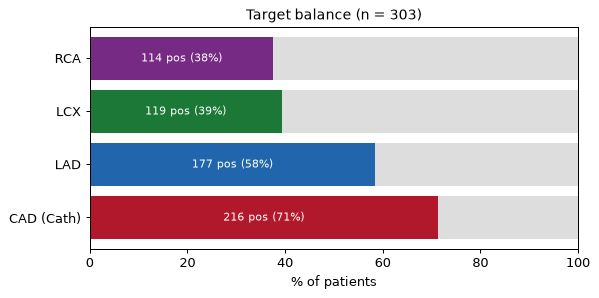

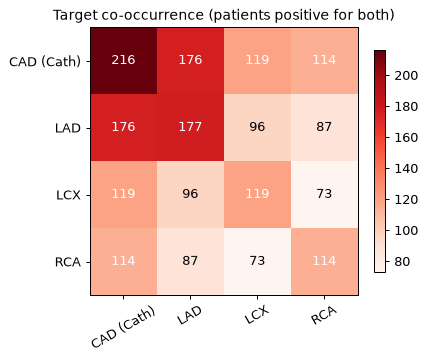

In [8]:
show_fig(P.target_balance(Y), "eda_target_balance")
show_fig(P.cooccurrence(Y), "eda_vessel_cooccurrence")

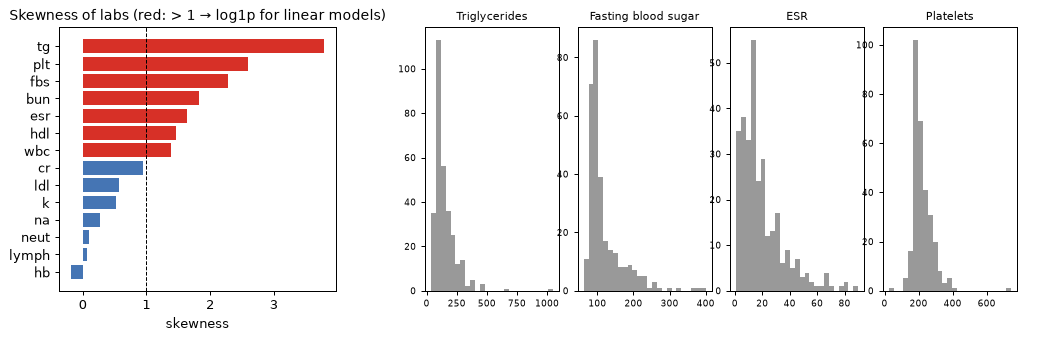

{'tg': 3.78, 'plt': 2.59, 'fbs': 2.28, 'bun': 1.82, 'esr': 1.63, 'hdl': 1.46, 'wbc': 1.39, 'cr': 0.95, 'ldl': 0.57, 'k': 0.53, 'na': 0.26, 'neut': 0.09, 'lymph': 0.07, 'hb': -0.18}


In [9]:
labs = ["tg", "fbs", "cr", "esr", "bun", "wbc", "plt", "ldl", "hdl", "hb", "k", "na", "lymph", "neut"]
skew = df[labs].skew().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[1, 2.2]))
axes[0].barh(skew.index[::-1], skew.values[::-1], color=["#d73027" if s > 1 else "#4575b4" for s in skew.values[::-1]])
axes[0].axvline(1, ls="--", c="k", lw=0.8)
axes[0].set(title="Skewness of labs (red: > 1 → log1p for linear models)", xlabel="skewness")
for i, c in enumerate(["tg", "fbs", "esr", "plt"]):
    ax = axes[1].inset_axes([i * 0.25, 0, 0.22, 1])
    ax.hist(df[c], bins=25, color="#999999")
    ax.set_title(C.FEATURES[c]["label"], fontsize=9)
    ax.tick_params(labelsize=7)
axes[1].axis("off")
show_fig(fig, "eda_lab_skewness")
print(skew.round(2).to_dict())

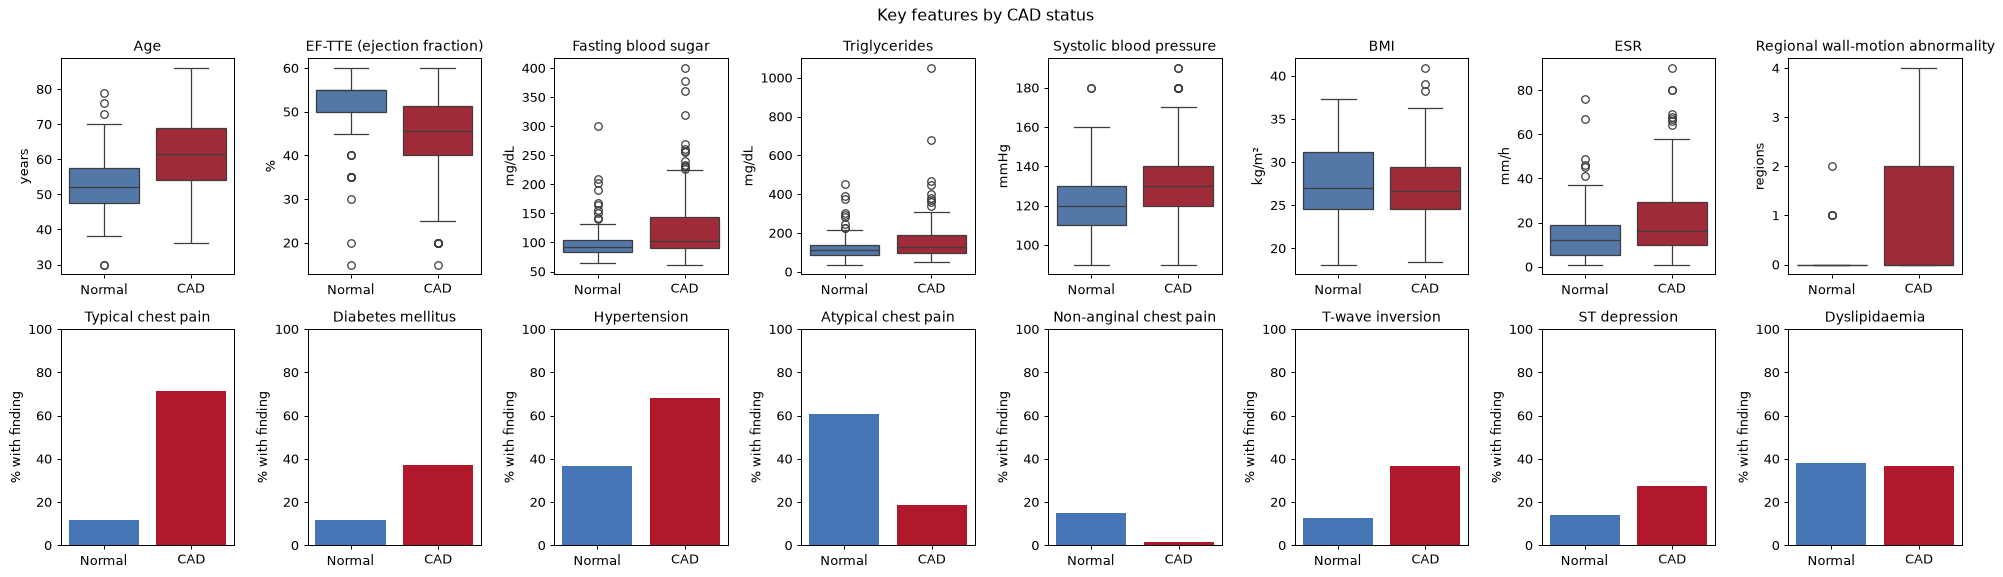

In [10]:
num_keys = ["age", "ef_tte", "fbs", "tg", "bp", "bmi", "esr", "region_rwma"]
bin_keys = ["typical_chest_pain", "dm", "htn", "atypical", "nonanginal", "tinversion", "st_depression", "dlp"]
fig, axes = plt.subplots(2, 8, figsize=(22, 6.5))
cad_lbl = Y.cad.map({1: "CAD", 0: "Normal"})
for ax, c in zip(axes[0], num_keys):
    sns.boxplot(x=cad_lbl, y=df[c], ax=ax, hue=cad_lbl, palette={"CAD": "#b2182b", "Normal": "#4575b4"},
                order=["Normal", "CAD"], legend=False)
    ax.set(title=C.FEATURES[c]["label"], xlabel="", ylabel=C.FEATURES[c]["unit"])
enc_all = encode_frame(get_features(df))
for ax, c in zip(axes[1], bin_keys):
    rate = enc_all[c].groupby(cad_lbl).mean().reindex(["Normal", "CAD"]) * 100
    ax.bar(rate.index, rate.values, color=["#4575b4", "#b2182b"])
    ax.set(title=C.FEATURES[c]["label"], ylabel="% with finding", ylim=(0, 100))
fig.suptitle("Key features by CAD status", fontsize=13)
fig.tight_layout()
show_fig(fig, "eda_features_by_cad")

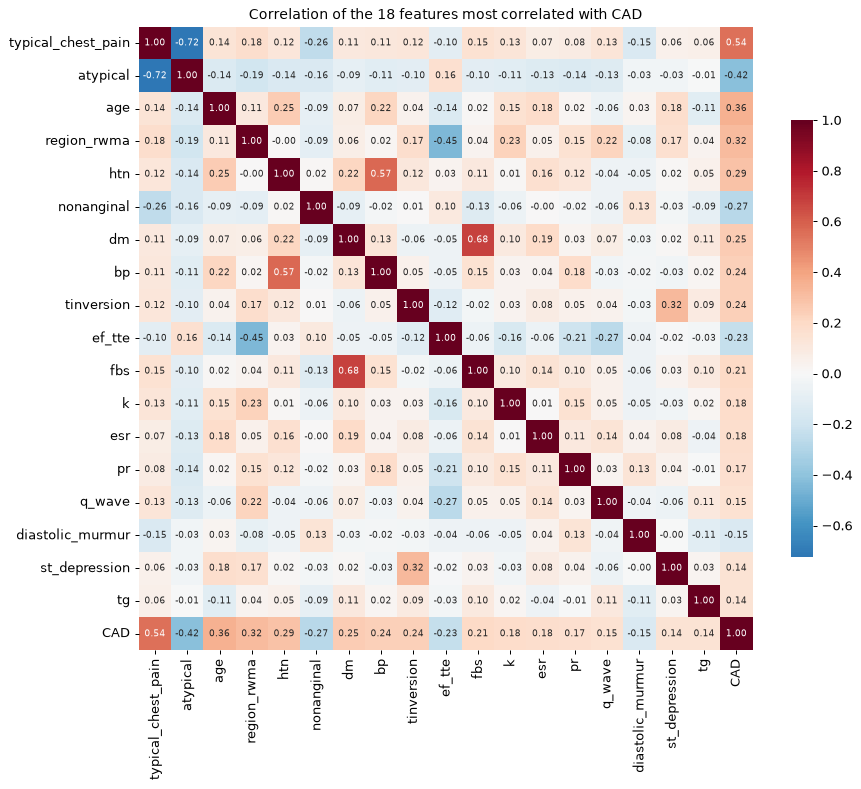

In [11]:
corr_df = enc_all.assign(CAD=Y.cad)
top = corr_df.corr()["CAD"].abs().drop("CAD").sort_values(ascending=False).index[:18].tolist()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_df[top + ["CAD"]].corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Correlation of the 18 features most correlated with CAD")
show_fig(fig, "eda_correlation_heatmap")

---
## Step 2: Preprocessing and feature engineering
### 2.0 Hold-out split first
We split **before** fitting anything: a stratified 20% hold-out on `Cath` with a fixed seed (details in 3.1).
Feature-schema ranges and defaults, SHAP backgrounds and all fitted transforms come from the 80% training
split only.

In [12]:
X = get_features(df)
assert_no_leakage(X)
tr_idx, te_idx = holdout_split(Y.cad)
Xtr, Xte = X.iloc[tr_idx], X.iloc[te_idx]
Ytr, Yte = Y.iloc[tr_idx], Y.iloc[te_idx]
json.dump(dict(seed=C.SEED, test_size=C.TEST_SIZE, stratify="Cath", n_train=len(tr_idx), n_test=len(te_idx),
               train_idx=tr_idx.tolist(), test_idx=te_idx.tolist()),
          open(C.ARTIFACTS_DIR / "split.json", "w"), indent=1)
split_check = pd.DataFrame({"train_%": (Ytr.mean() * 100).round(1), "holdout_%": (Yte.mean() * 100).round(1)})
split_check.loc["n_vessels_mean"] = [n_stenotic(Ytr).mean().round(2), n_stenotic(Yte).mean().round(2)]
print(f"train={len(Xtr)}  hold-out={len(Xte)}  (saved split.json)")
split_check

train=242  hold-out=61  (saved split.json)


,train_%,holdout_%
cad,71.50,70.50
lad,59.10,55.70
lcx,38.40,42.60
rca,38.80,32.80
n_vessels_mean,1.36,1.31


### 2.1 Encoding (deterministic, inside the pipeline)
| Column(s) | Encoding |
|---|---|
| Y/N binary columns | 1 / 0 |
| Sex (`Male` / `Fmale`, typo in the source) | 1 / 0 |
| BBB (N / LBBB / RBBB) | one-hot `bbb_lbbb`, `bbb_rbbb` (N = reference) |
| VHD | ordinal N=0, mild=1, Moderate=2, Severe=3 |
| Region RWMA | ordinal 0–4 (**clinical echo feature only**, never an anatomical coordinate or lesion map) |
| Function Class | ordinal 0–3 |
| Exertional CP | dropped (constant) |

The encoder also accepts already-numeric inputs (e.g. `0/1`, BBB `0/1/2`), so the dashboard and LIME can call
the same pipeline.

In [13]:
enc = ClinicalEncoder().fit_transform(Xtr)
print("encoded shape:", enc.shape)
cp_cols = ["typical_chest_pain", "atypical", "nonanginal", "lowth_ang"]
cp_sum = enc[["typical_chest_pain", "atypical", "nonanginal"]].sum(axis=1)
print("Chest-pain flags per patient (Typical/Atypical/Nonanginal):", cp_sum.value_counts().sort_index().to_dict())
display(pd.crosstab(enc.typical_chest_pain, enc.lowth_ang))
enc.head()

encoded shape: (242, 55)
Chest-pain flags per patient (Typical/Atypical/Nonanginal): {0.0: 25, 1.0: 217}


lowth_ang,0.0,1.0
typical_chest_pain,,
0.0,111,0
1.0,130,1


,age,weight,length,sex,bmi,dm,htn,current_smoker,ex_smoker,fh,obesity,crf,cva,airway_disease,thyroid_disease,chf,dlp,bp,pr,edema,...,poor_r_progression,bbb_lbbb,bbb_rbbb,fbs,cr,tg,ldl,hdl,bun,esr,hb,k,na,wbc,lymph,neut,plt,ef_tte,region_rwma,vhd
1,67.0,70.0,157.0,0.0,28.398718,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,140.0,80.0,1.0,...,0.0,0.0,0.0,80.0,1.0,309.0,121.0,36.0,30.0,26.0,13.9,4.7,156.0,7700.0,38.0,55.0,165.0,40.0,4.0,0.0
2,54.0,54.0,164.0,1.0,20.077335,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,100.0,0.0,...,0.0,0.0,0.0,85.0,1.0,103.0,70.0,45.0,17.0,10.0,13.5,4.7,139.0,7400.0,38.0,60.0,230.0,40.0,2.0,1.0
3,66.0,67.0,158.0,0.0,26.838648,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,80.0,0.0,...,0.0,0.0,0.0,78.0,1.2,63.0,55.0,27.0,30.0,76.0,12.1,4.4,142.0,13000.0,18.0,72.0,742.0,55.0,0.0,3.0
5,50.0,75.0,175.0,1.0,24.489796,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,118.0,70.0,0.0,...,0.0,0.0,0.0,86.0,1.0,139.0,119.0,34.0,13.0,18.0,15.6,4.2,141.0,7300.0,26.0,66.0,194.0,50.0,0.0,0.0
7,72.0,80.0,175.0,1.0,26.122449,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,130.0,70.0,0.0,...,0.0,0.0,0.0,130.0,0.9,80.0,90.0,55.0,19.0,4.0,16.1,4.3,142.0,12200.0,25.0,74.0,410.0,45.0,4.0,1.0


**Chest pain.** The Typical/Atypical/Non-anginal flags are *almost* mutually exclusive. In the training split
every patient has at most one flag, and some have none. In the full data 2 of 303 patients have two flags.
Low-threshold angina mostly occurs together with typical pain. We keep all original
flags and add an ordinal `chest_pain_type` (0 none, 1 non-anginal, 2 atypical, 3 typical) with the precedence
typical > atypical > non-anginal for the rare overlaps. This mirrors how a clinician would classify the
dominant symptom, and it is the input to the Diamond–Forrester table.

### 2.2 Engineered features (`cardio_ml/features.py`, fitted inside every fold)
* **Clinical composites:** `risk_factor_count`, `ecg_abnormal_count`, `ischemic_ecg`, `rwma_present`, `ef_category`.
* **Pretest probability:** Diamond & Forrester (N Engl J Med 1979;300:1350–8), age band × sex × chest-pain type,
  as tabulated in the ACC/AHA 2002 chronic stable angina guideline (Gibbons et al., Table 4). Ages < 30 and ≥ 70
  are clamped to the nearest band.
* **Lab ratios** (divide-by-zero guarded): `tg_hdl`, `ldl_hdl`, `nlr`, `abs_lymph`, `plr`, and `egfr` from
  CKD-EPI 2021 (race-free). We **assume creatinine is in mg/dL**: the observed range is 0.5–2.2, which is
  consistent with mg/dL.
* **Transforms:** `log1p` on right-skewed labs and ratios, then standardisation, for linear and SVM models only.
* **Collinearity:** BMI = weight / height², and Obesity = BMI ≥ 25. Linear and SVM models keep BMI only.
  Tree models keep all three.

In [14]:
eng = ClinicalFeatureEngineer().fit_transform(enc)
new_cols = [c for c in eng.columns if c not in enc.columns]
from sklearn.metrics import roc_auc_score
uni = pd.DataFrame({
    "label": [C.ENGINEERED_LABELS.get(c, c) for c in new_cols],
    "mean": eng[new_cols].mean().round(3).values,
    "min": eng[new_cols].min().round(3).values, "max": eng[new_cols].max().round(3).values,
    "train AUC vs CAD": [round(max(a, 1 - a), 3) for a in (roc_auc_score(Ytr.cad, eng[c]) for c in new_cols)],
}, index=new_cols)
print("engineered features:", len(new_cols), "| total model inputs (trees):", eng.shape[1])
uni.sort_values("train AUC vs CAD", ascending=False)

engineered features: 13 | total model inputs (trees): 68


,label,mean,min,max,train AUC vs CAD
pretest_prob,Diamond–Forrester pretest probability,0.638,0.003,0.943,0.833
chest_pain_type,Chest-pain type,2.289,0.000,3.000,0.798
ecg_abnormal_count,ECG abnormality count,0.764,0.000,3.000,0.664
rwma_present,RWMA present,0.281,0.000,1.000,0.656
risk_factor_count,Risk-factor count,2.360,0.000,5.000,0.649
ischemic_ecg,Ischaemic ECG,0.413,0.000,1.000,0.647
ef_category,EF category,1.455,0.000,2.000,0.638
tg_hdl,TG/HDL ratio,3.932,0.500,23.864,0.582
nlr,Neutrophil/lymphocyte ratio,2.264,0.582,12.143,0.576
egfr,eGFR (CKD-EPI 2021),75.118,28.941,118.229,0.571


`pretest_prob` (Diamond–Forrester) on its own already gives a training AUC around 0.8 for CAD. This is good
evidence that the encoding of age, sex and chest pain is clinically right.

### 2.3 Feature-schema export → `feature_schema.json`
The schema lists every **raw** input with its original name, physiological group, type, allowed values or
training range, default (median or mode), unit and a readable label. The groups drive the dashboard's
"physiological breakdown".

In [15]:
schema = build_feature_schema(Xtr, name_map)
(C.ARTIFACTS_DIR / "feature_schema.json").write_text(json.dumps(schema, indent=1, ensure_ascii=False), encoding="utf-8")
pd.DataFrame(schema["features"]).set_index("name")[["original_name", "group", "type", "unit", "default", "min", "max"]].head(60)

,original_name,group,type,unit,default,min,max
name,,,,,,,
age,Age,demographic,numeric,years,57.0,30.000000,86.000000
weight,Weight,demographic,numeric,kg,74.0,48.000000,120.000000
length,Length,demographic,numeric,cm,165.0,145.000000,188.000000
sex,Sex,demographic,binary,,Male,NaN,NaN
bmi,BMI,demographic,numeric,kg/m²,26.84,18.365473,40.900658
dm,DM,risk factor,binary,,0,NaN,NaN
htn,HTN,risk factor,binary,,1,NaN,NaN
current_smoker,Current Smoker,risk factor,binary,,0,NaN,NaN
ex_smoker,EX-Smoker,risk factor,binary,,0,NaN,NaN


---
## Step 3: Modelling
### 3.1 Validation design
* **Hold-out:** 20% stratified on Cath (2.0), saved in `split.json`, used **once** at the very end (3.5).
* **Outer CV on the 80% training split:** repeated stratified 5-fold × 5 repeats. We stratify on the
  *number of stenotic vessels* (0–3). This also stratifies CAD and keeps all three vessel targets balanced
  in every fold. **All models, strategies, ablations and calibration variants use these same splits.**
* **Nested tuning:** Optuna TPE runs on an inner 3-fold CV of each outer-train split (≤ 50 trials). The
  decision threshold of each fold is chosen on an inner 5-fold OOF, so the outer-test fold never selects
  anything.
* **Everything happens inside the fold pipeline:** encoding → feature engineering → (log/scale) →
  (feature selection) → (SMOTE) → model.
* Metrics are reported as **CV mean ± std**. Hold-out metrics get **95% bootstrap CIs (1000 resamples)**.

In [16]:
strat = n_stenotic(Ytr).to_numpy()
splits = outer_splits(strat)
print(f"{len(splits)} outer folds | train fold ≈ {len(splits[0][0])} | test fold ≈ {len(splits[0][1])}")
pd.DataFrame([{t: Ytr[t].to_numpy()[te].mean().round(2) for t in C.TARGETS} for _, te in splits[:5]],
             index=[f"fold {i}" for i in range(5)])

25 outer folds | train fold ≈ 193 | test fold ≈ 49


,cad,lad,lcx,rca
fold 0,0.69,0.59,0.41,0.37
fold 1,0.71,0.57,0.35,0.45
fold 2,0.71,0.54,0.42,0.38
fold 3,0.73,0.65,0.35,0.38
fold 4,0.73,0.60,0.40,0.38


### 3.2 Model zoo with nested CV, for every model and every target
The registry (`cardio_ml/models.py`) holds L1/ElasticNet logistic regression (class-balanced), RBF-SVM,
Random Forest, Extra Trees, LightGBM (early stopping inside each training fold), XGBoost (fold-wise
`scale_pos_weight`), CatBoost (`auto_class_weights="Balanced"`) and TabPFN v2 when it is available. Imbalance is
handled with class weights first. SMOTE is tested afterwards as a variant.

In [17]:
ok, why = tabpfn_status()
print("TabPFN:", "available" if ok else f"SKIPPED -> {why}")
MODELS = available_models()
print("models:", MODELS)

zoo = {}
for t in C.TARGETS:
    zoo[t] = {}
    for m in MODELS:
        t1 = time.time()
        zoo[t][m] = nested_cv(m, Xtr, Ytr[t].to_numpy(), splits, cache_key=f"nested_{t}_{m}")
        print(f"{t:>3} {m:>6}: nested-CV AUC {zoo[t][m].summary(Ytr[t])['auc_mean']:.3f}  ({time.time() - t1:.0f}s)")

TabPFN: SKIPPED -> tabpfn.errors.TabPFNLicenseError: TabPFN requires a one-time license acceptance to download
models: ['lr', 'svm', 'rf', 'et', 'lgbm', 'xgb', 'cat']
cad     lr: nested-CV AUC 0.943  (0s)


cad    svm: nested-CV AUC 0.945  (0s)
cad     rf: nested-CV AUC 0.931  (0s)


cad     et: nested-CV AUC 0.932  (0s)
cad   lgbm: nested-CV AUC 0.925  (0s)


cad    xgb: nested-CV AUC 0.937  (0s)
cad    cat: nested-CV AUC 0.936  (0s)


lad     lr: nested-CV AUC 0.865  (0s)
lad    svm: nested-CV AUC 0.869  (0s)


...

rca     rf: nested-CV AUC 0.713  (122s)


rca     et: nested-CV AUC 0.724  (73s)


rca   lgbm: nested-CV AUC 0.717  (18s)


rca    xgb: nested-CV AUC 0.722  (28s)


rca    cat: nested-CV AUC 0.714  (291s)


**Ensembles (model 8).** For each target we take the top 3 *diverse* single models: the best model of
different families (linear / kernel / bagging / boosting / PFN), ranked by nested-CV AUC. We combine them by
(a) soft voting and (b) stacking with a logistic-regression meta-learner trained **only on the members' inner
out-of-fold predictions**. Both are evaluated on the same outer folds, so their estimates are nested as well.
Choosing the top 3 by outer-CV AUC adds a small optimistic bias. We accept it, and the ensemble must still
clear the selection tolerance below.

In [18]:
def top_diverse(t, k=3):
    ranked = sorted(MODELS, key=lambda m: -zoo[t][m].summary(Ytr[t])["auc_mean"])
    chosen, fams = [], set()
    for m in ranked:
        if REGISTRY[m].family not in fams:
            chosen.append(m)
            fams.add(REGISTRY[m].family)
        if len(chosen) == k:
            break
    return chosen

zoo_tables, top3 = {}, {}
for t in C.TARGETS:
    top3[t] = top_diverse(t)
    members = [zoo[t][m] for m in top3[t]]
    zoo[t]["vote"] = ensemble_from_members(members, Ytr[t], "vote")
    zoo[t]["stack"] = ensemble_from_members(members, Ytr[t], "stack")
    rows = {}
    for m, res in zoo[t].items():
        s = res.summary(Ytr[t])
        s["complexity"] = REGISTRY[m].complexity if m in REGISTRY else ENSEMBLE_COMPLEXITY[m]
        rows[m] = s
    zoo_tables[t] = pd.DataFrame(rows).T

def zoo_display(t):
    tb = zoo_tables[t]
    return pd.DataFrame({k: [fmt(tb.loc[m, f"{k}_mean"], tb.loc[m, f"{k}_std"]) for m in tb.index]
                         for k in ["auc", "f1", "pr_auc", "brier", "recall", "precision"]},
                        index=tb.index).sort_values("auc", ascending=False)

best_model, best_single = {}, {}
for t in C.TARGETS:
    best_model[t] = select_best(zoo_tables[t])
    best_single[t] = select_best(zoo_tables[t].loc[[m for m in MODELS]])
    print(f"\n=== {C.TARGET_DISPLAY[t]}: nested CV (mean ± std over {len(splits)} outer folds) | "
          f"top-3 diverse = {top3[t]} | selected = {best_model[t]} | best single = {best_single[t]}")
    display(zoo_display(t))


=== CAD (Cath): nested CV (mean ± std over 25 outer folds) | top-3 diverse = ['svm', 'lr', 'xgb'] | selected = stack | best single = svm


,auc,f1,pr_auc,brier,recall,precision
vote,0.946 ± 0.034,0.908 ± 0.031,0.979 ± 0.015,0.094 ± 0.022,0.911 ± 0.048,0.908 ± 0.042
stack,0.945 ± 0.036,0.908 ± 0.032,0.979 ± 0.015,0.089 ± 0.028,0.909 ± 0.050,0.909 ± 0.042
svm,0.945 ± 0.034,0.905 ± 0.035,0.979 ± 0.014,0.095 ± 0.032,0.908 ± 0.055,0.904 ± 0.049
lr,0.943 ± 0.036,0.906 ± 0.033,0.979 ± 0.015,0.125 ± 0.034,0.896 ± 0.058,0.920 ± 0.044
xgb,0.937 ± 0.035,0.911 ± 0.029,0.974 ± 0.016,0.096 ± 0.026,0.919 ± 0.044,0.906 ± 0.041
cat,0.936 ± 0.036,0.909 ± 0.035,0.974 ± 0.016,0.102 ± 0.024,0.917 ± 0.052,0.905 ± 0.048
et,0.932 ± 0.037,0.907 ± 0.038,0.974 ± 0.015,0.113 ± 0.018,0.906 ± 0.049,0.910 ± 0.046
rf,0.931 ± 0.037,0.908 ± 0.031,0.972 ± 0.018,0.111 ± 0.017,0.917 ± 0.042,0.901 ± 0.038
lgbm,0.925 ± 0.047,0.906 ± 0.029,0.966 ± 0.025,0.111 ± 0.035,0.928 ± 0.045,0.887 ± 0.039



=== LAD: nested CV (mean ± std over 25 outer folds) | top-3 diverse = ['svm', 'cat', 'lr'] | selected = svm | best single = svm


,auc,f1,pr_auc,brier,recall,precision
vote,0.872 ± 0.053,0.849 ± 0.034,0.904 ± 0.048,0.150 ± 0.019,0.900 ± 0.041,0.805 ± 0.048
stack,0.872 ± 0.053,0.852 ± 0.036,0.904 ± 0.049,0.141 ± 0.023,0.907 ± 0.046,0.806 ± 0.050
svm,0.869 ± 0.053,0.844 ± 0.033,0.901 ± 0.054,0.145 ± 0.026,0.877 ± 0.060,0.817 ± 0.055
cat,0.868 ± 0.051,0.844 ± 0.037,0.897 ± 0.052,0.153 ± 0.025,0.901 ± 0.058,0.797 ± 0.046
lr,0.865 ± 0.051,0.848 ± 0.045,0.902 ± 0.050,0.176 ± 0.026,0.907 ± 0.048,0.799 ± 0.056
et,0.859 ± 0.062,0.847 ± 0.044,0.891 ± 0.057,0.154 ± 0.023,0.912 ± 0.044,0.794 ± 0.067
rf,0.858 ± 0.055,0.844 ± 0.039,0.889 ± 0.056,0.157 ± 0.018,0.902 ± 0.048,0.795 ± 0.056
xgb,0.857 ± 0.056,0.842 ± 0.046,0.885 ± 0.058,0.153 ± 0.026,0.898 ± 0.071,0.796 ± 0.055
lgbm,0.846 ± 0.065,0.832 ± 0.047,0.874 ± 0.063,0.168 ± 0.034,0.899 ± 0.068,0.779 ± 0.064



=== LCX: nested CV (mean ± std over 25 outer folds) | top-3 diverse = ['rf', 'cat', 'svm'] | selected = rf | best single = rf


,auc,f1,pr_auc,brier,recall,precision
rf,0.740 ± 0.069,0.641 ± 0.074,0.629 ± 0.105,0.206 ± 0.014,0.819 ± 0.105,0.535 ± 0.092
vote,0.739 ± 0.064,0.632 ± 0.072,0.631 ± 0.105,0.205 ± 0.013,0.820 ± 0.105,0.520 ± 0.077
stack,0.738 ± 0.064,0.623 ± 0.081,0.630 ± 0.100,0.205 ± 0.013,0.795 ± 0.123,0.519 ± 0.082
cat,0.738 ± 0.059,0.624 ± 0.081,0.625 ± 0.088,0.213 ± 0.021,0.819 ± 0.139,0.512 ± 0.076
xgb,0.737 ± 0.063,0.617 ± 0.082,0.643 ± 0.095,0.211 ± 0.028,0.735 ± 0.137,0.543 ± 0.098
lgbm,0.727 ± 0.062,0.615 ± 0.079,0.626 ± 0.090,0.223 ± 0.018,0.787 ± 0.145,0.515 ± 0.082
svm,0.718 ± 0.062,0.615 ± 0.073,0.605 ± 0.101,0.209 ± 0.015,0.799 ± 0.107,0.504 ± 0.070
lr,0.709 ± 0.059,0.607 ± 0.061,0.604 ± 0.094,0.227 ± 0.012,0.776 ± 0.075,0.505 ± 0.080
et,0.708 ± 0.060,0.629 ± 0.072,0.609 ± 0.087,0.217 ± 0.014,0.847 ± 0.095,0.504 ± 0.072



=== RCA: nested CV (mean ± std over 25 outer folds) | top-3 diverse = ['lr', 'svm', 'et'] | selected = vote | best single = lr


,auc,f1,pr_auc,brier,recall,precision
vote,0.737 ± 0.054,0.617 ± 0.055,0.653 ± 0.068,0.207 ± 0.011,0.812 ± 0.119,0.503 ± 0.052
lr,0.736 ± 0.060,0.621 ± 0.056,0.659 ± 0.071,0.216 ± 0.014,0.810 ± 0.131,0.511 ± 0.049
stack,0.736 ± 0.055,0.615 ± 0.056,0.653 ± 0.071,0.206 ± 0.015,0.824 ± 0.114,0.495 ± 0.050
svm,0.727 ± 0.058,0.622 ± 0.057,0.639 ± 0.072,0.205 ± 0.018,0.796 ± 0.140,0.519 ± 0.045
et,0.724 ± 0.058,0.612 ± 0.050,0.632 ± 0.088,0.215 ± 0.014,0.863 ± 0.085,0.477 ± 0.051
xgb,0.722 ± 0.068,0.610 ± 0.052,0.632 ± 0.072,0.218 ± 0.021,0.808 ± 0.118,0.498 ± 0.059
lgbm,0.717 ± 0.065,0.598 ± 0.050,0.621 ± 0.072,0.222 ± 0.016,0.790 ± 0.147,0.493 ± 0.061
cat,0.714 ± 0.061,0.615 ± 0.034,0.618 ± 0.073,0.218 ± 0.022,0.828 ± 0.099,0.495 ± 0.047
rf,0.713 ± 0.063,0.603 ± 0.047,0.617 ± 0.066,0.213 ± 0.015,0.804 ± 0.134,0.490 ± 0.048


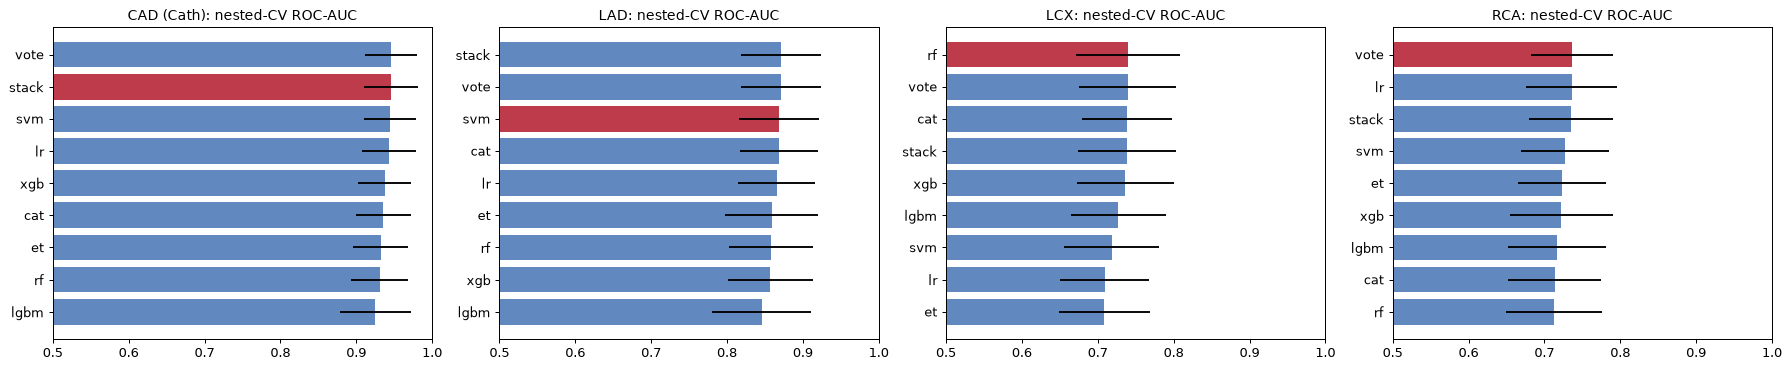

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), sharex=True)
for ax, t in zip(axes, C.TARGETS):
    tb = zoo_tables[t].sort_values("auc_mean")
    colors = ["#b2182b" if m == best_model[t] else "#4575b4" for m in tb.index]
    ax.barh(tb.index, tb.auc_mean, xerr=tb.auc_std, color=colors, alpha=0.85)
    ax.set(title=f"{C.TARGET_DISPLAY[t]}: nested-CV ROC-AUC", xlim=(0.5, 1.0))
fig.tight_layout()
show_fig(fig, "model_zoo_auc")

**Model selection rule** (`evaluation.select_best`), applied per target:
(1) keep models within 0.005 of the best mean CV ROC-AUC, (2) among those, within 0.01 of the best F1 at the
fold-tuned threshold, (3) among those, within 0.005 of the lowest Brier score, (4) pick the simplest
(LR < SVM < forests < boosting < PFN < vote < stack). The tolerances stop us from picking a "winner" whose lead
is far smaller than its fold-to-fold standard deviation.

**SMOTE variant.** We compare the best single model with and without SMOTE (imblearn pipeline, inside folds
only) on the same splits, using default hyper-parameters. SMOTE is kept only if mean AUC improves by ≥ 0.005.

In [20]:
smote_rows, use_smote = [], {}
for t in C.TARGETS:
    m = best_single[t]
    res = {s: cv_fixed(partial(build_pipeline, m, None, True, None, s), Xtr, Ytr[t], splits, with_oof=True,
                       name=f"{m}{'+smote' if s else ''}", cache_key=f"smote_{t}_{m}_{s}") for s in (False, True)}
    a = {s: r.summary(Ytr[t]) for s, r in res.items()}
    use_smote[t] = a[True]["auc_mean"] - a[False]["auc_mean"] >= 0.005
    smote_rows.append(dict(target=t, model=m, auc_class_weights=fmt(a[False]["auc_mean"], a[False]["auc_std"]),
                           auc_smote=fmt(a[True]["auc_mean"], a[True]["auc_std"]),
                           f1_class_weights=round(a[False]["f1_mean"], 3), f1_smote=round(a[True]["f1_mean"], 3),
                           keep_smote=use_smote[t]))
pd.DataFrame(smote_rows).set_index("target")

,model,auc_class_weights,auc_smote,f1_class_weights,f1_smote,keep_smote
target,,,,,,
cad,svm,0.933 ± 0.032,0.931 ± 0.034,0.903,0.901,False
lad,svm,0.857 ± 0.050,0.858 ± 0.049,0.837,0.835,False
lcx,rf,0.747 ± 0.069,0.728 ± 0.067,0.639,0.637,False
rca,lr,0.745 ± 0.060,0.739 ± 0.053,0.609,0.602,False


### 3.3 Multi-vessel strategy, compared on the same CV splits
* **A. Independent:** one model per vessel.
* **B. Classifier-chain ensemble:** chain order CAD → LAD → LCX → RCA plus 4 random orders. Downstream models
  see only *out-of-fold predicted* upstream probabilities.
* **C. Hierarchical:** P(vessel) = P(CAD) × P(vessel stenotic | CAD). The conditional model is trained on
  CAD-positive training patients only.

Each target uses its best single model family with default hyper-parameters, so the comparison is clean and
fast. Tuning is not part of this comparison. The winner is the strategy with the best mean vessel ROC-AUC,
subject to a tolerance like the one in model selection. A strategy counts as tied with the best if its mean
vessel AUC is within 0.01. Ties go to **C**, as the spec asks, because C guarantees P(vessel) ≤ P(CAD) on the
3D heart, then to **A**, the simplest. The 5-order chain (B) is adopted only if it wins by more than 0.01,
because its extra complexity (20 chained models, explanations routed through predicted probabilities) must
buy a real gain. The paired fold-wise difference against A is shown next to each strategy.

In [21]:
makeA = {t: partial(build_pipeline, best_single[t]) for t in C.TARGETS}
stratA = {v: cv_fixed(makeA[v], Xtr, Ytr[v], splits, with_oof=False, name=f"A:{v}",
                      cache_key=f"stratA_{v}_{best_single[v]}") for v in C.VESSELS}
stratB = cached("stratB_" + "_".join(best_single[t] for t in C.TARGETS),
                lambda: cv_chain(makeA, Xtr, Ytr, splits))
stratC = {v: cached(f"stratC_{v}_{best_single['cad']}_{best_single[v]}",
                    partial(cv_hierarchical, makeA["cad"], makeA[v], Xtr, Ytr.cad, Ytr[v], splits))
          for v in C.VESSELS}

def fold_auc(res, y):
    return res.fold_metrics(y)["auc"]

rows = {}
for name, d in [("A independent", stratA), ("B chain x5", {v: stratB[v] for v in C.VESSELS}), ("C hierarchical", stratC)]:
    aucs = {v: fold_auc(d[v], Ytr[v]) for v in C.VESSELS}
    r = {C.TARGET_DISPLAY[v]: fmt(aucs[v].mean(), aucs[v].std()) for v in C.VESSELS}
    r["mean vessel AUC"] = np.mean([aucs[v].mean() for v in C.VESSELS])
    r["mean vessel Brier"] = np.mean([d[v].fold_metrics(Ytr[v])["brier"].mean() for v in C.VESSELS])
    pc = np.concatenate(zoo["cad"][best_single["cad"]].test_probs)
    pv = np.column_stack([np.concatenate(d[v].test_probs) for v in C.VESSELS])
    r["% folds-preds P(vessel) > P(CAD)+0.1"] = round(float((pv.max(1) > pc + 0.1).mean() * 100), 1)
    rows[name] = r
strategy_table = pd.DataFrame(rows).T
auc_A = {v: fold_auc(stratA[v], Ytr[v]).to_numpy() for v in C.VESSELS}
for name, d in [("B chain x5", stratB), ("C hierarchical", stratC)]:
    diff = np.mean([fold_auc(d[v], Ytr[v]).to_numpy() - auc_A[v] for v in C.VESSELS], axis=0)
    strategy_table.loc[name, "paired Δ AUC vs A"] = fmt(diff.mean(), diff.std())
strategy_table.loc["A independent", "paired Δ AUC vs A"] = "-"
best_auc = strategy_table["mean vessel AUC"].max()
PREFERENCE = ["C hierarchical", "A independent", "B chain x5"]   # 3D-consistent, then simplest, then most complex
VESSEL_STRATEGY = next(s for s in PREFERENCE
                       if strategy_table.loc[s, "mean vessel AUC"] >= best_auc - C.VESSEL_STRATEGY_TOL)[0]
print(f"Chosen vessel strategy: {VESSEL_STRATEGY} (best mean vessel AUC {best_auc:.3f}, tolerance {C.VESSEL_STRATEGY_TOL})")
strategy_table

Chosen vessel strategy: A (best mean vessel AUC 0.786, tolerance 0.01)


,LAD,LCX,RCA,mean vessel AUC,mean vessel Brier,% folds-preds P(vessel) > P(CAD)+0.1,paired Δ AUC vs A
A independent,0.857 ± 0.050,0.747 ± 0.069,0.745 ± 0.060,0.783327,0.184423,17.0,-
B chain x5,0.857 ± 0.049,0.752 ± 0.066,0.748 ± 0.060,0.785691,0.183312,14.2,0.002 ± 0.007
C hierarchical,0.857 ± 0.059,0.744 ± 0.063,0.717 ± 0.054,0.772583,0.183542,6.1,-0.011 ± 0.019


The last column measures **3D-view consistency**: how often a vessel's probability exceeds the (nested-CV) CAD
probability by more than 10 points. That would be an incoherent picture, for example a red LAD on a heart
whose overall CAD risk is low. Strategy C rules this out by construction.

`expected_stenotic_vessels` = P(LAD) + P(LCX) + P(RCA) (range 0–3) is derived from the chosen strategy.

### 3.4 Feature selection, ablation, calibration, thresholds and risk tiers
#### 3.4a Feature selection (inside the folds only)
Variants: all features, SHAP top-k (k = 10, 15, 20, from mean |SHAP| of a small LightGBM fitted on the fold's
training part) and L1-logistic selection. We keep the **smallest** set within 0.01 AUC of the best variant.

In [22]:
SELECTORS = [None, "shap10", "shap15", "shap20", "l1"]
fs_rows, SELECTOR = [], {}
for t in C.TARGETS:
    m = best_single[t]
    res = {s: cv_fixed(partial(build_pipeline, m, None, True, s, use_smote[t]), Xtr, Ytr[t], splits,
                       with_oof=False, name=str(s), cache_key=f"fs_{t}_{m}_{s}_{use_smote[t]}") for s in SELECTORS}
    full_cols = build_pipeline(m, None, True, None).fit(Xtr, Ytr[t]).named_steps["engineer"].feature_names_out_
    nfeat = {None: len(full_cols)}
    for s in SELECTORS[1:]:
        Zt = build_pipeline(m)[:2].fit_transform(Xtr)
        nfeat[s] = len(make_selector(s).fit(Zt, Ytr[t]).feature_names_out_)
    auc = {s: r.fold_metrics(Ytr[t])["auc"] for s, r in res.items()}
    best = max(a.mean() for a in auc.values())
    ok_sets = [s for s in SELECTORS if auc[s].mean() >= best - C.FEATURE_SELECTION_TOL]
    SELECTOR[t] = min(ok_sets, key=lambda s: (nfeat[s], SELECTORS.index(s)))
    for s in SELECTORS:
        fs_rows.append(dict(target=t, model=m, selector=str(s), n_features=nfeat[s],
                            auc=fmt(auc[s].mean(), auc[s].std()), chosen=s == SELECTOR[t]))
pd.DataFrame(fs_rows).set_index(["target", "selector"])

model  n_features            auc  chosen
target selector                                         
cad    None       svm          68  0.933 ± 0.032    True
       shap10     svm          10  0.915 ± 0.044   False
       shap15     svm          15  0.921 ± 0.039   False
       shap20     svm          20  0.923 ± 0.036   False
       l1         svm          16  0.918 ± 0.047   False
lad    None       svm          68  0.857 ± 0.050    True
       shap10     svm          10  0.836 ± 0.063   False
       shap15     svm          15  0.845 ± 0.053   False
       shap20     svm          20  0.840 ± 0.054   False
       l1         svm          16  0.828 ± 0.054   False
lcx    None        rf          68  0.747 ± 0.069   False
       shap10      rf          10  0.734 ± 0.074   False
       shap15      rf          15  0.741 ± 0.078    True
       shap20      rf          20  0.744 ± 0.067   False
       l1          rf          15  0.711 ± 0.066   False
rca    None        lr          68  0.745 ± 0.060   False
       shap10      lr          10  0.748 ± 0.052    True
       shap15      lr          15  0.748 ± 0.057   False
       shap20      lr          20  0.747 ± 0.059   False
       l1          lr          15  0.748 ± 0.064   False

#### Final configuration per target
The family or ensemble comes from 3.2, SMOTE from 3.2, the selector from 3.4a and the vessel strategy from 3.3.

In [23]:
def make_config(t, params=None):
    bm = best_model[t]
    if bm in ("vote", "stack"):
        members = [(m, {}) for m in top3[t]]
        kind = bm
    else:
        members, kind = [(bm, {})], "single"
    cfg = ModelConfig(kind, members, True, SELECTOR[t], use_smote[t])
    return cfg.with_params(params) if params else cfg

CONFIG = {t: make_config(t) for t in C.TARGETS}
pd.DataFrame({t: dict(model=CONFIG[t].label, selector=CONFIG[t].selector, smote=CONFIG[t].smote,
                      vessel_strategy=(VESSEL_STRATEGY if t in C.VESSELS else "-"))
              for t in C.TARGETS}).T

,model,selector,smote,vessel_strategy
cad,stack(svm+lr+xgb),None,False,-
lad,svm,None,False,A
lcx,rf,shap15,False,A
rca,vote(lr+svm+et),shap10,False,A


#### 3.4b Ablation → `ablation.json`
Each row adds one component, using default hyper-parameters on the same outer folds:
(1) raw encoded features → (2) + engineered features → (3) + feature selection → (4) + soft-vote ensemble of the
top-3 diverse families → (5) + vessel strategy (vessels only).

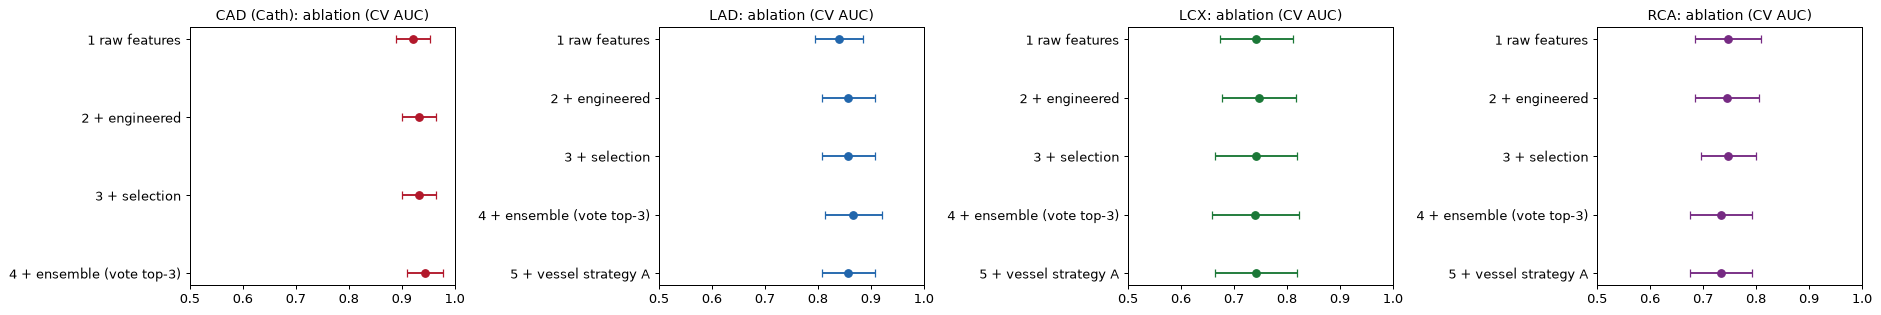

auc_mean  auc_std  brier_mean
cad 1 raw features                0.921    0.033       0.101
    2 + engineered                0.933    0.032       0.095
    3 + selection                 0.933    0.032       0.095
    4 + ensemble (vote top-3)     0.944    0.034       0.091
lad 1 raw features                0.839    0.046       0.157
    2 + engineered                0.857    0.050       0.148
    3 + selection                 0.857    0.050       0.148
    4 + ensemble (vote top-3)     0.867    0.054       0.144
    5 + vessel strategy A         0.857    0.050       0.148
lcx 1 raw features                0.743    0.069       0.205
    2 + engineered                0.747    0.069       0.202
    3 + selection                 0.741    0.078       0.201
    4 + ensemble (vote top-3)     0.740    0.082       0.201
    5 + vessel strategy A         0.741    0.078       0.201
rca 1 raw features                0.746    0.062       0.206
    2 + engineered                0.745    0.060       0.204
    3 + selection                 0.748    0.052       0.204
    4 + ensemble (vote top-3)     0.734    0.058       0.206
    5 + vessel strategy A         0.734    0.058       0.206

In [24]:
ablation = {}
for t in C.TARGETS:
    m, s, sm = best_single[t], SELECTOR[t], use_smote[t]
    steps = {
        "1 raw features": partial(build_pipeline, m, None, False, None, sm),
        "2 + engineered": partial(build_pipeline, m, None, True, None, sm),
        "3 + selection": partial(build_pipeline, m, None, True, s, sm),
        "4 + ensemble (vote top-3)": partial(build_ensemble, [(x, {}) for x in top3[t]], "vote", True, s, sm),
    }
    ablation[t] = {}
    for k, mk in steps.items():
        r = cv_fixed(mk, Xtr, Ytr[t], splits, with_oof=False, name=k, cache_key=f"abl_{t}_{k[:1]}_" + key_of(m, s, sm, top3[t]))
        a = r.fold_metrics(Ytr[t])
        ablation[t][k] = dict(auc_mean=a.auc.mean(), auc_std=a.auc.std(), brier_mean=a.brier.mean())
    if t in C.VESSELS:
        if VESSEL_STRATEGY == "C":
            r = cv_hierarchical(CONFIG["cad"].build, CONFIG[t].build, Xtr, Ytr.cad, Ytr[t], splits)
        elif VESSEL_STRATEGY == "B":
            r = stratB[t]
        else:
            r = cv_fixed(CONFIG[t].build, Xtr, Ytr[t], splits, with_oof=False)
        a = r.fold_metrics(Ytr[t])
        ablation[t][f"5 + vessel strategy {VESSEL_STRATEGY}"] = dict(auc_mean=a.auc.mean(), auc_std=a.auc.std(),
                                                                     brier_mean=a.brier.mean())
json.dump(ablation, open(C.ARTIFACTS_DIR / "ablation.json", "w"), indent=1)

fig, axes = plt.subplots(1, 4, figsize=(21, 3.6))
for ax, t in zip(axes, C.TARGETS):
    ab = pd.DataFrame(ablation[t]).T
    ax.errorbar(ab.auc_mean, range(len(ab)), xerr=ab.auc_std, fmt="o", color=P.PALETTE[t], capsize=3)
    ax.set_yticks(range(len(ab)), ab.index)
    ax.invert_yaxis()
    ax.set(title=f"{C.TARGET_DISPLAY[t]}: ablation (CV AUC)", xlim=(0.5, 1.0))
fig.tight_layout()
show_fig(fig, "ablation")
pd.concat({t: pd.DataFrame(v).T.round(3) for t, v in ablation.items()})

#### 3.4c Calibration (risk-estimation quality)
The probabilities colour the 3D vessels, so they need to be calibrated as well as ranked well. We compare
no calibration, `CalibratedClassifierCV(method="sigmoid")` and `method="isotonic"`, both with `ensemble=False`
(one refitted model plus one calibrator fitted on its 5-fold cross-validated predictions, all inside the
outer-training fold). For hierarchical vessels, both factors are calibrated. We pick the lowest mean Brier
score. Ties within 0.002 go to sigmoid, which has 2 parameters and is safer than isotonic on about 190 rows.

chosen calibration: {'cad': 'sigmoid', 'lad': 'sigmoid', 'lcx': 'sigmoid', 'rca': 'sigmoid'}


auc   brier  brier_std     ece
target method                                            
cad    None      0.944 ± 0.035  0.0880     0.0250  0.0352
       sigmoid   0.944 ± 0.035  0.0882     0.0283  0.0329
       isotonic  0.936 ± 0.040  0.0912     0.0325  0.0316
lad    None      0.857 ± 0.050  0.1480     0.0272  0.0418
       sigmoid   0.857 ± 0.050  0.1483     0.0276  0.0291
       isotonic  0.855 ± 0.050  0.1501     0.0306  0.0344
lcx    None      0.741 ± 0.078  0.2011     0.0200  0.0551
       sigmoid   0.741 ± 0.078  0.2012     0.0239  0.0322
       isotonic  0.734 ± 0.073  0.2059     0.0290  0.0458
rca    None      0.734 ± 0.058  0.2062     0.0170  0.0733
       sigmoid   0.734 ± 0.058  0.2053     0.0210  0.0451
       isotonic  0.721 ± 0.054  0.2110     0.0258  0.0504

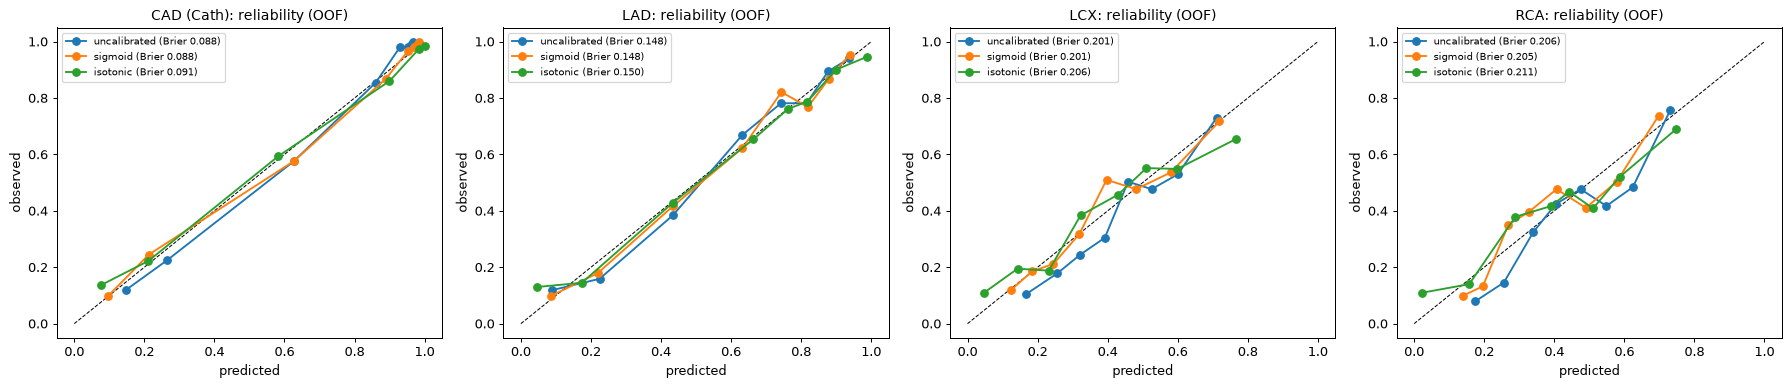

In [25]:
METHODS = [None, "sigmoid", "isotonic"]
cal_res, CAL = {}, {}

def cv_target(t, method_t, method_cad=None, cfgs=None, key=None):
    cfgs = cfgs or CONFIG
    if t in C.VESSELS and VESSEL_STRATEGY == "C":
        mk = partial(cv_hierarchical, calibrated(cfgs["cad"].build, method_cad),
                     calibrated(cfgs[t].build, method_t), Xtr, Ytr.cad, Ytr[t], splits)
    else:
        mk = partial(cv_fixed, calibrated(cfgs[t].build, method_t), Xtr, Ytr[t], splits, with_oof=False)
    return cached(key, mk) if key else mk()

cal_rows = []
for t in C.TARGETS:
    cal_res[t] = {}
    for mth in METHODS:
        cal_res[t][mth] = cv_target(t, mth, CAL.get("cad"), key=f"cal_{t}_{mth}_" + key_of(CAL.get("cad"), CONFIG[t], CONFIG["cad"], VESSEL_STRATEGY))
        fm = cal_res[t][mth].fold_metrics(Ytr[t])
        yp, pp = cal_res[t][mth].pooled(Ytr[t])
        cal_rows.append(dict(target=t, method=str(mth), auc=fmt(fm.auc.mean(), fm.auc.std()),
                             brier=fm.brier.mean(), brier_std=fm.brier.std(), ece=ece(yp, pp)))
    sub = pd.DataFrame([r for r in cal_rows if r["target"] == t]).set_index("method")
    best_b = sub.brier.min()
    CAL[t] = "sigmoid" if sub.loc["sigmoid", "brier"] <= best_b + 0.002 else \
        {"None": None, "isotonic": "isotonic"}[sub.brier.idxmin()]
cal_table = pd.DataFrame(cal_rows).set_index(["target", "method"]).round(4)
print("chosen calibration:", CAL)
display(cal_table)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
for ax, t in zip(axes, C.TARGETS):
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    from sklearn.calibration import calibration_curve
    for mth in METHODS:
        yp, pp = cal_res[t][mth].pooled(Ytr[t])
        fx, fy = calibration_curve(yp, pp, n_bins=8, strategy="quantile")
        ax.plot(fy, fx, "o-", label=f"{mth or 'uncalibrated'} (Brier {np.mean((pp - yp) ** 2):.3f})")
    ax.set(title=f"{C.TARGET_DISPLAY[t]}: reliability (OOF)", xlabel="predicted", ylabel="observed")
    ax.legend(fontsize=8)
fig.tight_layout()
show_fig(fig, "calibration_reliability")

#### 3.4d Final tuning on the full 80% split, then thresholds and risk tiers
Each member of each final configuration is tuned with Optuna on the whole training split (5-fold CV, up to 50
trials). For hierarchical vessels, the conditional model is tuned on CAD-positive training patients only.
Thresholds and risk tiers come from the **out-of-fold** predictions of the final calibrated configuration
on the same outer splits.

In [26]:
def subset_for(t):
    if t in C.VESSELS and VESSEL_STRATEGY == "C":
        pos = Ytr.cad.to_numpy() == 1
        return Xtr[pos], Ytr[t].to_numpy()[pos]
    return Xtr, Ytr[t].to_numpy()

jobs, owners = [], []
for t in C.TARGETS:
    Xs, ys = subset_for(t)
    pk = dict(engineered=True, selector=CONFIG[t].selector, smote=CONFIG[t].smote)
    for name, _ in CONFIG[t].members:
        jobs.append((name, Xs, ys, pk))
        owners.append(t)
tuned = cached("final_tuning_" + key_of([CONFIG[t] for t in C.TARGETS], VESSEL_STRATEGY),
               lambda: tune_members(jobs))
FINAL = {t: CONFIG[t].with_params([p for o, p in zip(owners, tuned) if o == t]) for t in C.TARGETS}
for t in C.TARGETS:
    print(f"{t}: {FINAL[t].label} | calibration={CAL[t]} | params={FINAL[t].members}")

final_oof = {t: cv_target(t, CAL[t], CAL["cad"], cfgs=FINAL,
                          key=f"finaloof_{t}_" + key_of(CAL, FINAL[t], FINAL["cad"], VESSEL_STRATEGY))
             for t in C.TARGETS}

cad: stack(svm+lr+xgb) | calibration=sigmoid | params=[('svm', {'C': 1.0135761726471624, 'gamma': 0.00024277597963301916}), ('lr', {'C': 0.0011204692369739587, 'l1_ratio': 0.001306271939141521}), ('xgb', {'max_depth': 2, 'learning_rate': 0.09713317048862727, 'n_estimators': 450, 'subsample': 0.6204997142603736, 'colsample_bytree': 0.6907281680834626, 'min_child_weight': 6, 'reg_lambda': 4.0987758470625115, 'reg_alpha': 1.1891251804316931, 'gamma': 0.20958605909248107})]
lad: svm | calibration=sigmoid | params=[('svm', {'C': 2.8352513009385607, 'gamma': 0.00011706476592123182})]
lcx: rf | calibration=sigmoid | params=[('rf', {'n_estimators': 300, 'min_samples_leaf': 9, 'max_features': 0.3, 'max_depth': 12})]
rca: vote(lr+svm+et) | calibration=sigmoid | params=[('lr', {'C': 0.05342937261279776, 'l1_ratio': 0.2912291401980419}), ('svm', {'C': 0.7399771874994432, 'gamma': 0.002406294480179599}), ('et', {'n_estimators': 200, 'min_samples_leaf': 7, 'max_features': 'sqrt', 'max_depth': 4})]


In [27]:
thresholds = {}
for t in C.TARGETS:
    yp, pp = final_oof[t].pooled(Ytr[t])
    thr = best_f1_threshold(yp, pp)
    thresholds[t] = dict(threshold=thr, rule="F1-optimal on pooled out-of-fold predictions",
                         oof_metrics_at_threshold={k: round(v, 4) for k, v in metrics_at(yp, pp, thr).items()})
yc, pc = final_oof["cad"].pooled(Ytr.cad)
thresholds["cad"]["youden"] = youden_threshold(yc, pc)
thresholds["cad"]["high_sensitivity"] = sensitivity_threshold(yc, pc, 0.90)
t_low = sensitivity_threshold(yc, pc, C.RISK_TIER_RULE["low_min_sensitivity"])
t_high = specificity_threshold(yc, pc, C.RISK_TIER_RULE["high_min_specificity"])
if t_low >= t_high:
    t_low, t_high = C.RISK_TIER_FALLBACK["low"], C.RISK_TIER_FALLBACK["high"]
tiers = dict(low=round(t_low, 3), high=round(t_high, 3), rule=C.RISK_TIER_RULE)
tier_of = lambda p: np.where(p >= tiers["high"], "High", np.where(p < tiers["low"], "Low", "Moderate"))
tier_tab = pd.crosstab(tier_of(pc), yc, margins=True).rename(columns={0: "Normal", 1: "CAD"})
tier_tab["observed CAD rate"] = (tier_tab["CAD"] / tier_tab["All"]).round(3)
thresholds["risk_tiers"] = {**tiers, "oof_tier_table": tier_tab.reset_index().to_dict(orient="records")}
(C.ARTIFACTS_DIR / "thresholds.json").write_text(json.dumps(thresholds, indent=1, default=float), encoding="utf-8")

print({t: round(thresholds[t]["threshold"], 3) for t in C.TARGETS})
print("CAD Youden:", round(thresholds["cad"]["youden"], 3), "| CAD high-sensitivity (recall>=0.90):",
      round(thresholds["cad"]["high_sensitivity"], 3))
print("Risk tiers: Low < %.3f <= Moderate < %.3f <= High" % (tiers["low"], tiers["high"]))
tier_tab.reindex(["Low", "Moderate", "High", "All"])

{'cad': 0.195, 'lad': 0.465, 'lcx': 0.29, 'rca': 0.275}
CAD Youden: 0.641 | CAD high-sensitivity (recall>=0.90): 0.293
Risk tiers: Low < 0.077 <= Moderate < 0.820 <= High


col_0,Normal,CAD,All,observed CAD rate
row_0,,,,
Low,209,43,252,0.171
Moderate,102,131,233,0.562
High,34,691,725,0.953
All,345,865,1210,0.715


**Risk-tier justification.** CAD prevalence in this referral cohort is about 71%, so fixed population cut-offs
such as 10% or 20% would put almost nobody in "Low". The tiers are therefore set by error budgets on the
out-of-fold CAD probabilities. **Low** is everything below the largest threshold that still catches ≥ 95% of
CAD patients, so at most 5% of CAD patients are labelled Low. **High** starts at the smallest threshold with
≥ 90% specificity, so at most 10% of non-CAD patients are labelled High. The table above shows the observed
CAD rate in each tier. The rule is defined in `config.RISK_TIER_RULE` and the cut-offs are saved in
`thresholds.json`.

### 3.5 Final evaluation: hold-out set, used **once**
Each final calibrated pipeline is refit on the full 80% training split and scored once on the 61 hold-out
patients at the OOF-derived thresholds.

In [28]:
def fit_final(t, Xfit, Yfit, cad_model=None):
    if t in C.VESSELS and VESSEL_STRATEGY == "B":
        raise NotImplementedError("chain deployment (strategy B) is not implemented; see 3.3")
    if t in C.VESSELS and VESSEL_STRATEGY == "C":
        pos = Yfit.cad.to_numpy() == 1
        cond = calibrated(FINAL[t].build, CAL[t])().fit(Xfit[pos], Yfit[t].to_numpy()[pos])
        return HierarchicalVesselModel(cad_model, cond)
    return calibrated(FINAL[t].build, CAL[t])().fit(Xfit, Yfit[t].to_numpy())

final_models = {"cad": fit_final("cad", Xtr, Ytr)}
for v in C.VESSELS:
    final_models[v] = fit_final(v, Xtr, Ytr, final_models["cad"])

hold_probs = {t: final_models[t].predict_proba(Xte)[:, 1] for t in C.TARGETS}
holdout = {t: bootstrap_ci(Yte[t].to_numpy(), hold_probs[t], thresholds[t]["threshold"]) for t in C.TARGETS}
hold_tab = pd.DataFrame({t: {k: f"{v['value']:.3f} [{v['ci_low']:.3f}, {v['ci_high']:.3f}]"
                             for k, v in holdout[t].items()} for t in C.TARGETS}).T
hold_tab.index = [C.TARGET_DISPLAY[t] for t in C.TARGETS]
print("Hold-out (n=%d), point estimate [95%% bootstrap CI, 1000 resamples]" % len(Xte))
hold_tab[["accuracy", "precision", "recall", "specificity", "f1", "auc", "pr_auc", "brier"]]

Hold-out (n=61), point estimate [95% bootstrap CI, 1000 resamples]


,accuracy,precision,recall,specificity,f1,auc,pr_auc,brier
CAD (Cath),"0.852 [0.787, 0.918]","0.827 [0.768, 0.896]","1.000 [1.000, 1.000]","0.500 [0.278, 0.722]","0.905 [0.869, 0.945]","0.895 [0.806, 0.966]","0.952 [0.912, 0.986]","0.118 [0.067, 0.175]"
LAD,"0.754 [0.656, 0.852]","0.721 [0.644, 0.816]","0.912 [0.824, 1.000]","0.556 [0.370, 0.741]","0.805 [0.734, 0.877]","0.832 [0.725, 0.930]","0.845 [0.746, 0.945]","0.166 [0.110, 0.223]"
LCX,"0.672 [0.573, 0.770]","0.568 [0.500, 0.658]","0.962 [0.885, 1.000]","0.457 [0.286, 0.629]","0.714 [0.641, 0.788]","0.768 [0.647, 0.878]","0.644 [0.526, 0.836]","0.193 [0.156, 0.233]"
RCA,"0.623 [0.508, 0.738]","0.459 [0.375, 0.562]","0.850 [0.700, 1.000]","0.512 [0.366, 0.659]","0.596 [0.491, 0.702]","0.741 [0.598, 0.868]","0.572 [0.421, 0.781]","0.191 [0.144, 0.241]"


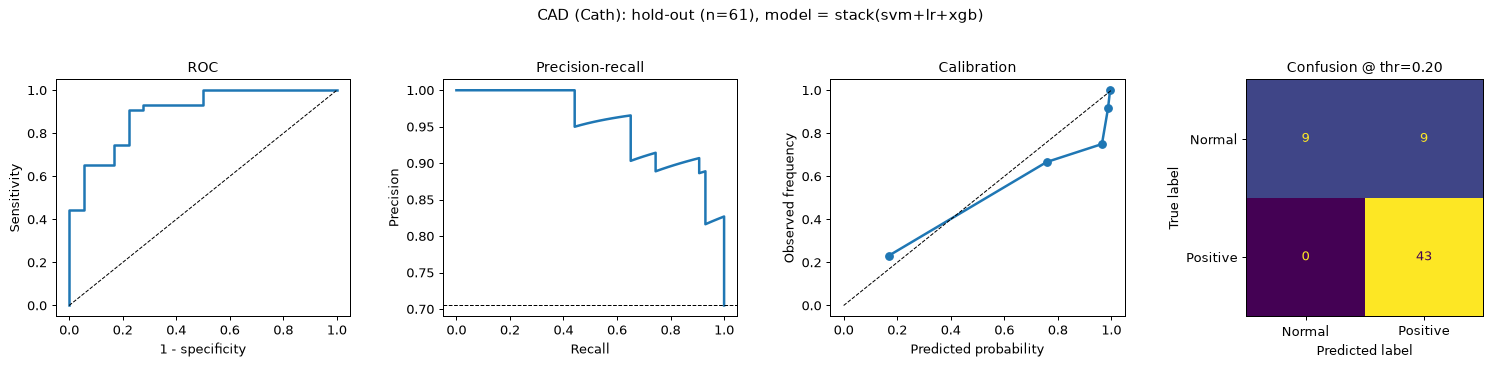

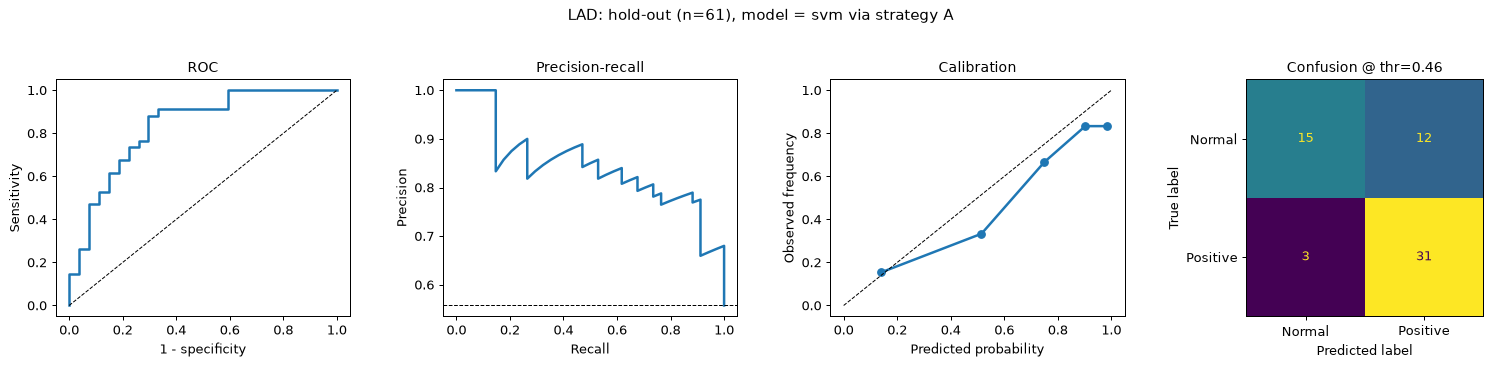

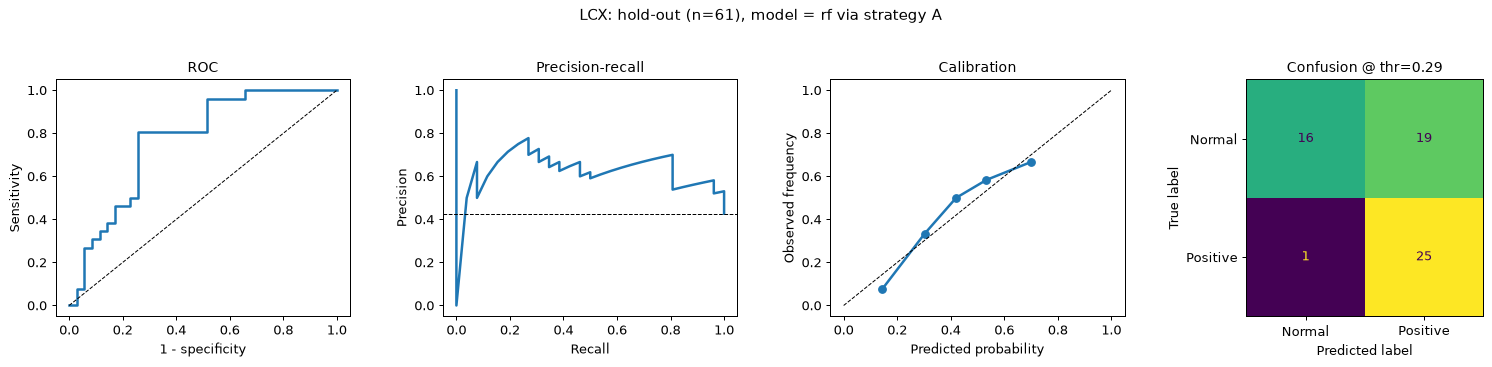

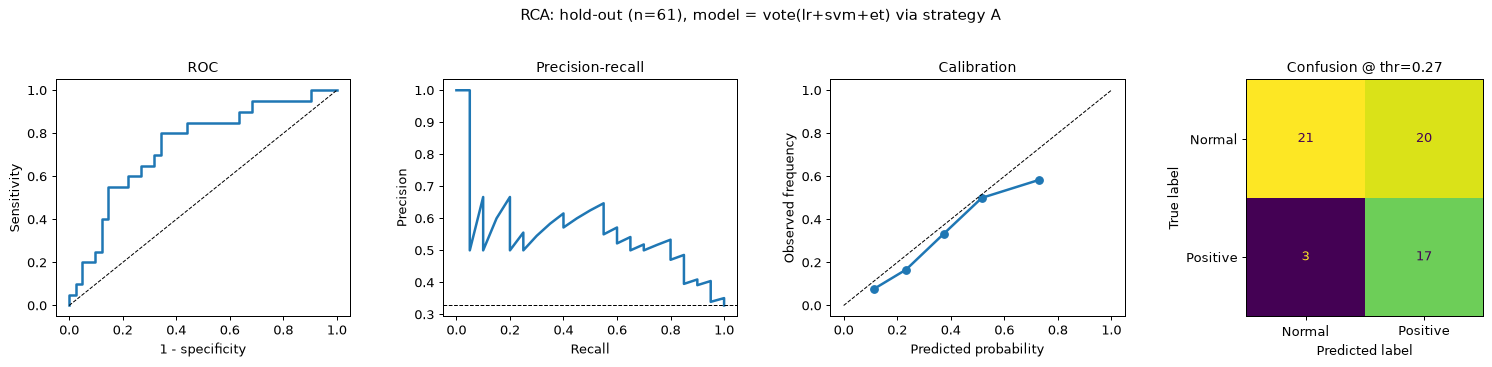

In [29]:
for t in C.TARGETS:
    fig = P.roc_pr_cal_cm(Yte[t].to_numpy(), hold_probs[t], thresholds[t]["threshold"],
                          f"{C.TARGET_DISPLAY[t]}: hold-out (n={len(Xte)}), model = {FINAL[t].label}"
                          + (f" via strategy {VESSEL_STRATEGY}" if t in C.VESSELS else ""))
    show_fig(fig, f"holdout_{t}")

**Save and verify the deployment artifacts.** The models evaluated above are the ones we deploy: they are
fitted on the 80% training split. We do **not** refit on all 303 rows, so the reported hold-out metrics describe
exactly the shipped models. Each `models/<target>.joblib` is a complete pipeline (encoding → features →
selection → model → calibration). Hierarchical vessel files embed their CAD model. We reload them in a
**fresh Python process** to prove they work outside this notebook.

In [30]:
for t, m in final_models.items():
    joblib.dump(m, C.MODELS_DIR / f"{t}.joblib")
check = f"""
import joblib, json, numpy as np
from cardio_ml.data import load_raw, get_features
from cardio_ml import config as C
df, _ = load_raw(); X = get_features(df); te = json.load(open(C.ARTIFACTS_DIR / 'split.json'))['test_idx']
print(json.dumps({{t: joblib.load(C.MODELS_DIR / f'{{t}}.joblib').predict_proba(X.iloc[te])[:, 1].round(6).tolist()
                  for t in C.TARGETS}}))
"""
out = subprocess.run([sys.executable, "-c", check], capture_output=True, text=True, cwd=str(C.ROOT))
fresh = json.loads(out.stdout.strip().splitlines()[-1])
for t in C.TARGETS:
    assert np.allclose(fresh[t], hold_probs[t].round(6), atol=1e-6), t
print("Reloaded all 4 models in a fresh process: predictions identical ✔")

Reloaded all 4 models in a fresh process: predictions identical ✔


---
## Step 4: Explainability (PS requirements 3b, 3c)
### 4.1 Primary explainer: SHAP
| Component | Explainer |
|---|---|
| RF / ET / LightGBM / XGBoost / CatBoost | `shap.TreeExplainer` (exact TreeSHAP) |
| Logistic regression | `shap.LinearExplainer` |
| SVM / TabPFN | `shap.PermutationExplainer` (50-row background), or a LightGBM surrogate for real-time use (4.7) |
| Ensembles / calibration / hierarchy | each member is explained with its native explainer and then combined (see below) |

For ensembles we do not run one slow permutation explainer on the whole black box. Each member gets its exact
native explainer, and the attributions are propagated through the ensemble weights, the calibrator and (for
vessels) the product P(CAD)·P(vessel|CAD) with a local secant approximation. Finally they are rescaled so
that each patient's contributions sum to *P(patient) − mean P(background)*. **Units are probability points.**
The background is 50 real training patients chosen as k-means medoids.

In [31]:
from sklearn.cluster import KMeans
D = encode_for_display(Xtr)
Ds = (D - D.mean()) / D.std(ddof=0).replace(0, 1)
km = KMeans(C.SHAP_BACKGROUND_SIZE, random_state=C.SEED, n_init=10).fit(Ds)
medoid_pos = sorted({int(np.argmin(((Ds.to_numpy() - c) ** 2).sum(1))) for c in km.cluster_centers_})
background = Xtr.iloc[medoid_pos]
joblib.dump(dict(background=background, train=Xtr), C.ARTIFACTS_DIR / "shap_background.joblib")
explainers = build_explainers(final_models, background, Xtr, mode="fast")
print("background rows:", len(background))
pd.DataFrame({t: dict(methods=", ".join(e.methods),
                      surrogate_R2=[round(m.fidelity_r2, 3) for e2 in ([e.cad, e.cond] if hasattr(e, "cond") else [e])
                                    for m in e2.members if m.fidelity_r2 is not None] or "-")
              for t, e in explainers.items()}).T

background rows: 50


,methods,surrogate_R2
cad,"surrogate, linear, tree",[0.916]
lad,surrogate,[0.908]
lcx,tree,-
rca,"linear, surrogate, tree",[0.98]


In [32]:
def explain_set(Xs):
    out = {"cad": explainers["cad"].explain_raw(Xs)}
    for v in C.VESSELS:
        e = explainers[v]
        out[v] = e.explain_raw(Xs, cad_result=out["cad"]) if hasattr(e, "cond") else e.explain_raw(Xs)
    return out

hold_expl = explain_set(Xte)
for t in C.TARGETS:
    assert np.allclose(hold_expl[t][0], hold_probs[t]), "explainer must reproduce model probabilities"
    resid = (hold_expl[t][1].sum(1) + explainers[t].p_ref - hold_probs[t]).abs()
    print(f"{t}: additivity |Σ contributions + base − P| median={resid.median():.2e}, "
          f"exact for {(resid < 1e-6).mean() * 100:.0f}% of patients (others: secant fallback)")

cad: additivity |Σ contributions + base − P| median=2.08e-17, exact for 97% of patients (others: secant fallback)


lad: additivity |Σ contributions + base − P| median=0.00e+00, exact for 95% of patients (others: secant fallback)
lcx: additivity |Σ contributions + base − P| median=0.00e+00, exact for 95% of patients (others: secant fallback)
rca: additivity |Σ contributions + base − P| median=4.16e-17, exact for 90% of patients (others: secant fallback)


### 4.2 Secondary explainer: LIME (cross-check)
We run `lime_tabular` on 5 hold-out patients per target, in the same raw-feature space, and compare its top-5
features with SHAP's top-5. Agreement is reported as overlap (out of 5) and as rank correlation.

In [33]:
lime_rows = []
rng = np.random.default_rng(C.SEED)
lime_idx = rng.choice(len(Xte), 5, replace=False)
for t in C.TARGETS:
    lime_top = lime_top_features(final_models[t], Xtr, Xte.iloc[lime_idx], k=5)
    for j, i in enumerate(lime_idx):
        shap_top = hold_expl[t][1].iloc[i].abs().sort_values(ascending=False).index[:5].tolist()
        lime_rows.append(dict(target=t, patient=int(Xte.index[i]), overlap_top5=len(set(shap_top) & set(lime_top[j])),
                              shap_top5=", ".join(shap_top), lime_top5=", ".join(lime_top[j])))
lime_df = pd.DataFrame(lime_rows)
print(lime_df.groupby("target").overlap_top5.agg(["mean", "min", "max"]).rename(columns={"mean": "mean overlap /5"}))
lime_df

        mean overlap /5  min  max
target                           
cad                 3.0    2    4
lad                 2.8    2    3
lcx                 3.4    3    4
rca                 3.2    3    4


,target,patient,overlap_top5,shap_top5,lime_top5
0,cad,215,2,"typical_chest_pain, fbs, atypical, esr, ef_tte","typical_chest_pain, fbs, htn, st_depression, t..."
1,cad,122,3,"age, ef_tte, esr, fbs, typical_chest_pain","typical_chest_pain, age, htn, tinversion, fbs"
2,cad,183,4,"typical_chest_pain, ef_tte, age, atypical, fbs","typical_chest_pain, ef_tte, htn, fbs, age"
3,cad,14,3,"ef_tte, typical_chest_pain, fbs, atypical, esr","typical_chest_pain, ef_tte, htn, fbs, age"
4,cad,296,3,"typical_chest_pain, age, fbs, atypical, ef_tte","typical_chest_pain, age, htn, fbs, esr"
5,lad,215,2,"q_wave, typical_chest_pain, ef_tte, region_rwm...","typical_chest_pain, st_elevation, region_rwma,..."
6,lad,122,3,"region_rwma, atypical, typical_chest_pain, age...","typical_chest_pain, tinversion, st_depression,..."
7,lad,183,3,"typical_chest_pain, ef_tte, region_rwma, atypi...","typical_chest_pain, region_rwma, tinversion, e..."
8,lad,14,3,"atypical, typical_chest_pain, ef_tte, lymph, r...","typical_chest_pain, region_rwma, tinversion, e..."
9,lad,296,3,"atypical, typical_chest_pain, age, region_rwma...","typical_chest_pain, region_rwma, tinversion, s..."


### 4.3 Mapping back to raw clinical features and physiological groups
One-hot columns (`bbb_lbbb`, `bbb_rbbb` → BBB) and engineered features (e.g. `tg_hdl` → TG and HDL,
`pretest_prob` → age, sex and chest-pain flags) are summed onto their raw sources using the map in
`config.ENGINEERED_SOURCES`. Features with several sources are split equally. Every explanation therefore uses
clinical names such as "Typical chest pain" or "EF-TTE", never `bbb_RBBB` or `tg_hdl`. These are then
aggregated into the six physiological groups: demographic, risk factor, examination, ECG, lab and echo.

### 4.4 Global and local plots, per target

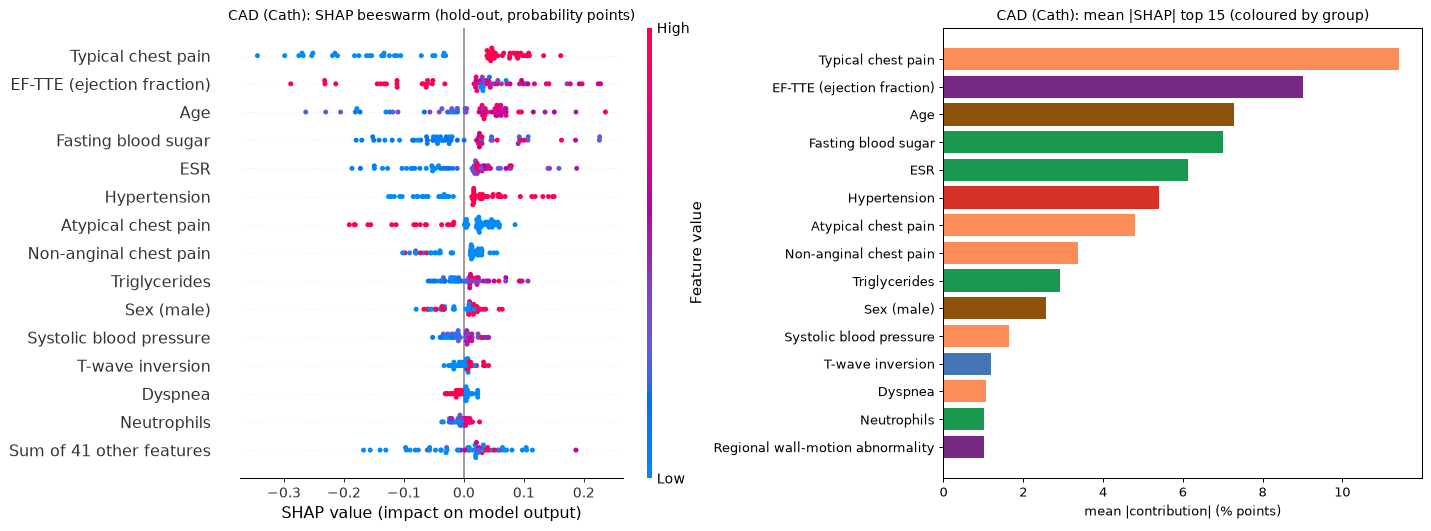

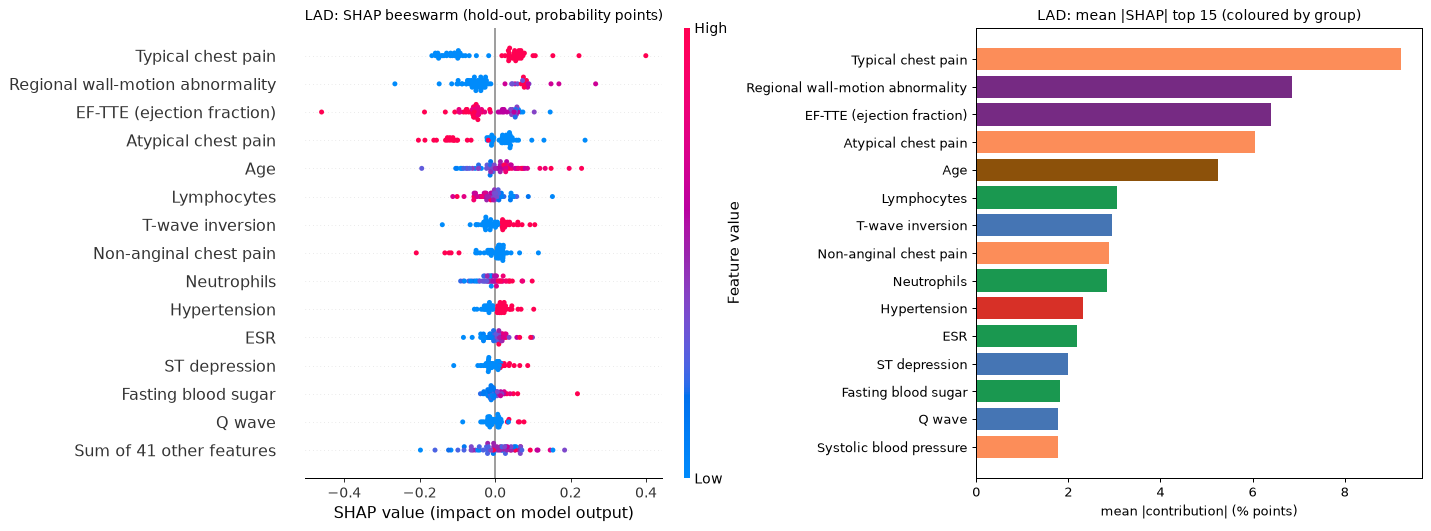

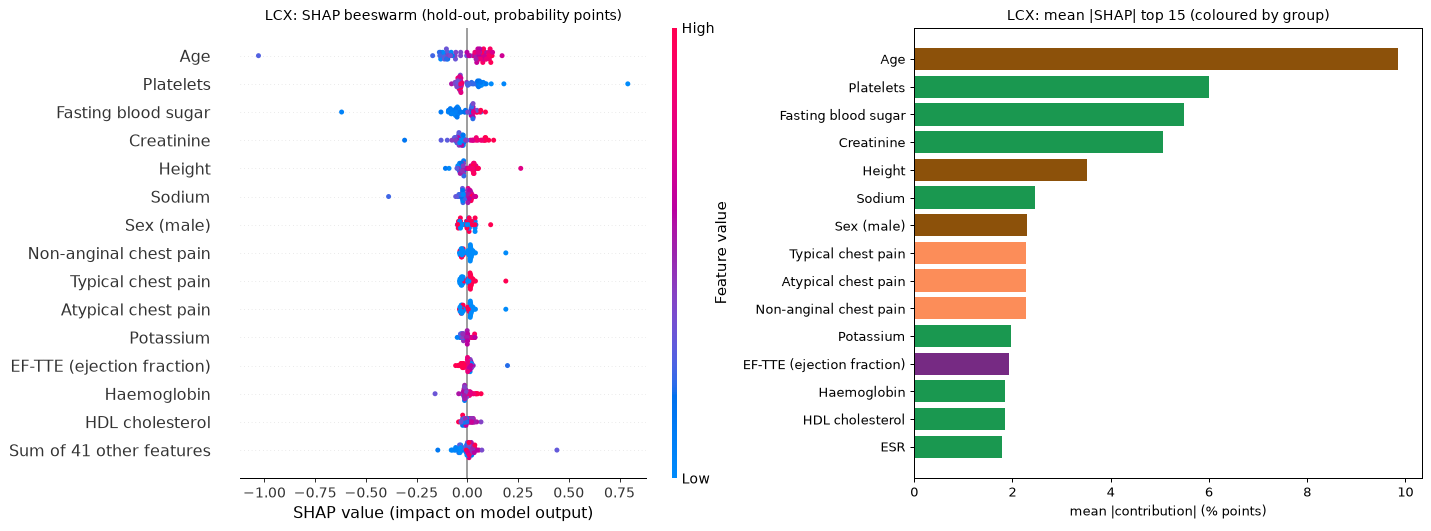

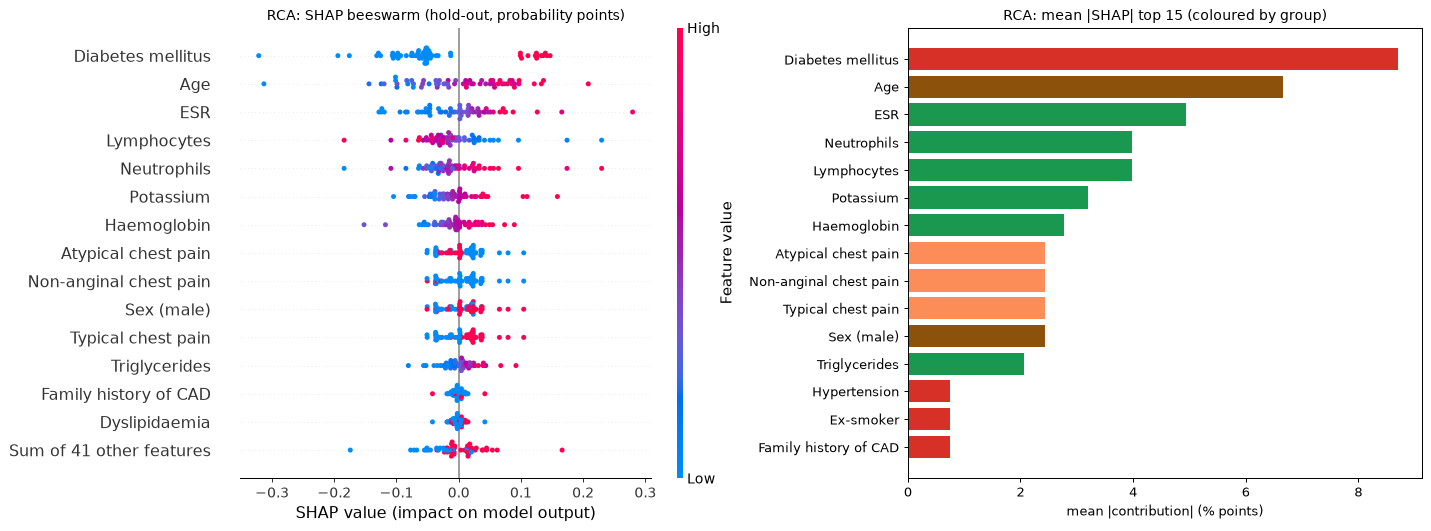

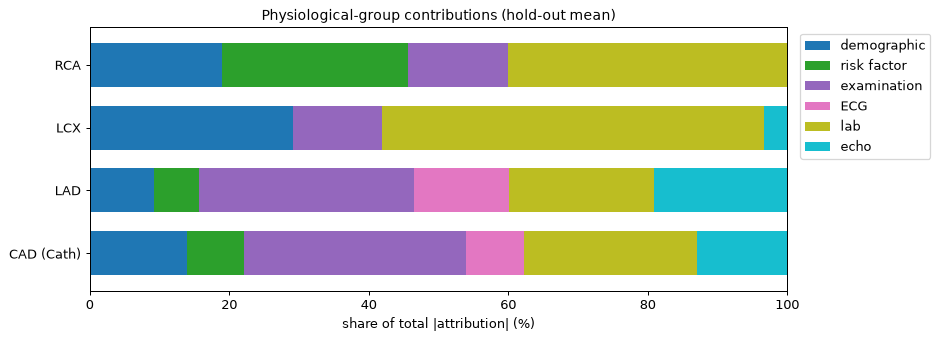

,demographic,risk factor,examination,ECG,lab,echo
CAD (Cath),14.0,8.2,31.7,8.4,24.8,12.9
LAD,9.3,6.4,30.9,13.5,20.9,19.0
LCX,29.1,0.0,12.8,0.0,54.7,3.4
RCA,18.9,26.7,14.3,0.0,40.1,0.0


In [34]:
glob_imp = {}
for t in C.TARGETS:
    P_, contrib = hold_expl[t]
    expl = shap_explanation(contrib, Xte, explainers[t].p_ref)
    glob_imp[t] = contrib.abs().mean().sort_values(ascending=False)
    fig = plt.figure(figsize=(16, 6))
    ax1 = fig.add_subplot(1, 2, 1)
    shap.plots.beeswarm(expl, max_display=15, show=False, plot_size=None, ax=ax1)
    ax1.set_title(f"{C.TARGET_DISPLAY[t]}: SHAP beeswarm (hold-out, probability points)")
    ax2 = fig.add_subplot(1, 2, 2)
    top15 = glob_imp[t].iloc[:15][::-1]
    ax2.barh([C.FEATURES[f]["label"] for f in top15.index], top15.values * 100,
             color=[{"demographic": "#8c510a", "risk factor": "#d73027", "examination": "#fc8d59",
                     "ECG": "#4575b4", "lab": "#1a9850", "echo": "#762a83"}[C.FEATURES[f]["group"]] for f in top15.index])
    ax2.set(title=f"{C.TARGET_DISPLAY[t]}: mean |SHAP| top 15 (coloured by group)", xlabel="mean |contribution| (% points)")
    fig.tight_layout()
    show_fig(fig, f"shap_global_{t}")

fig, ax = plt.subplots(figsize=(10, 3.8))
gt = pd.DataFrame({C.TARGET_DISPLAY[t]: group_totals(hold_expl[t][1]).mean() for t in C.TARGETS}).T
gt.plot.barh(stacked=True, ax=ax, colormap="tab10", width=0.7)
ax.set(xlabel="share of total |attribution| (%)", title="Physiological-group contributions (hold-out mean)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
show_fig(fig, "shap_group_contributions")
gt.round(1)

**Local waterfalls.** For each target we show one true positive, one true negative and one false negative
from the hold-out set, where such a case exists.

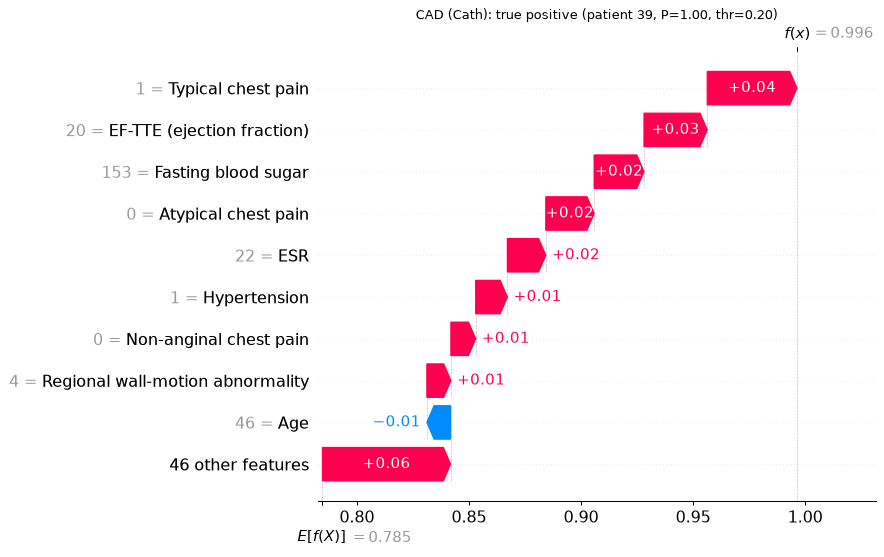

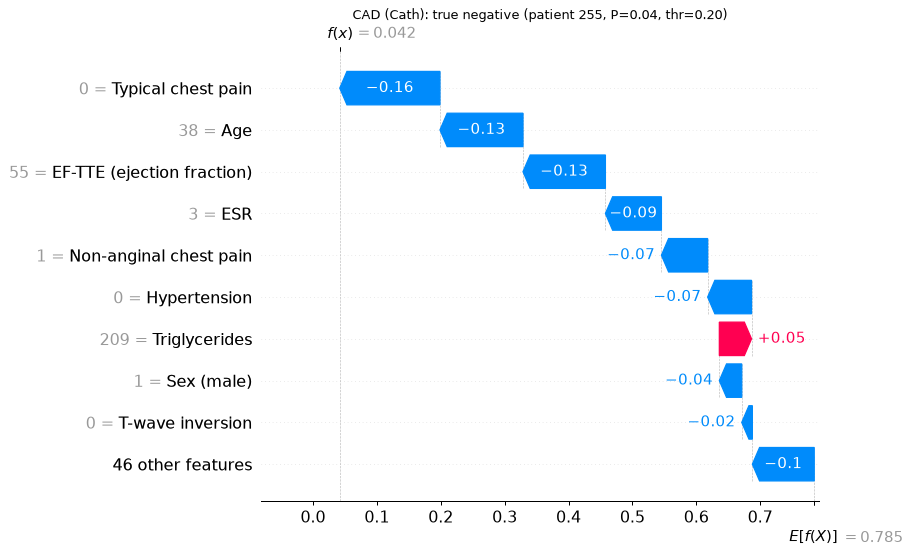

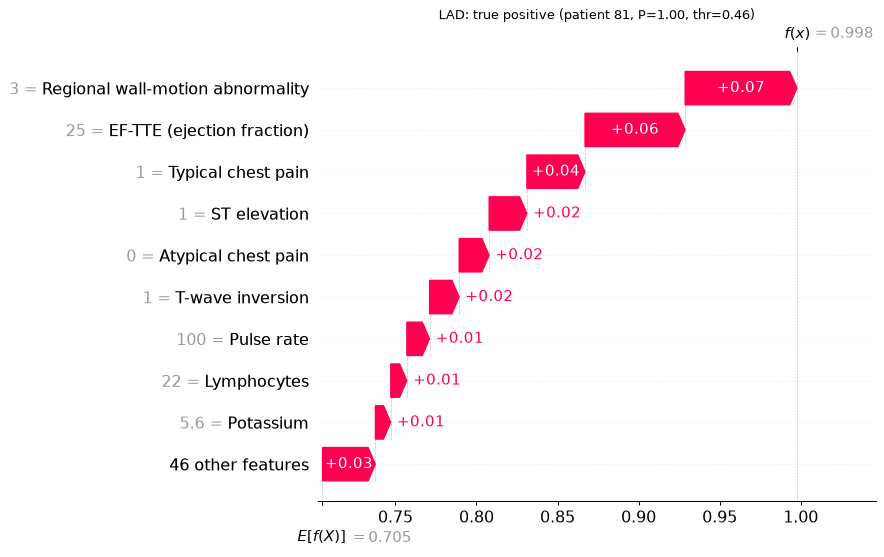

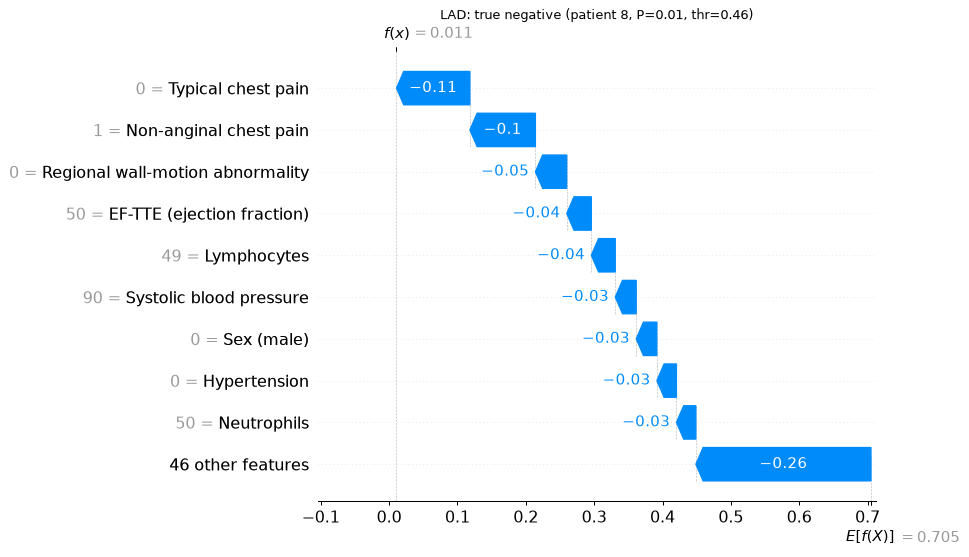

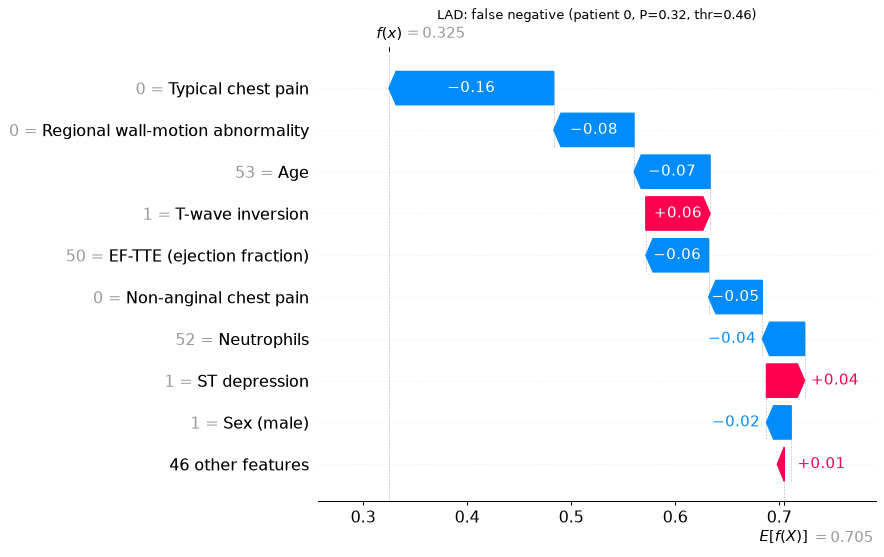

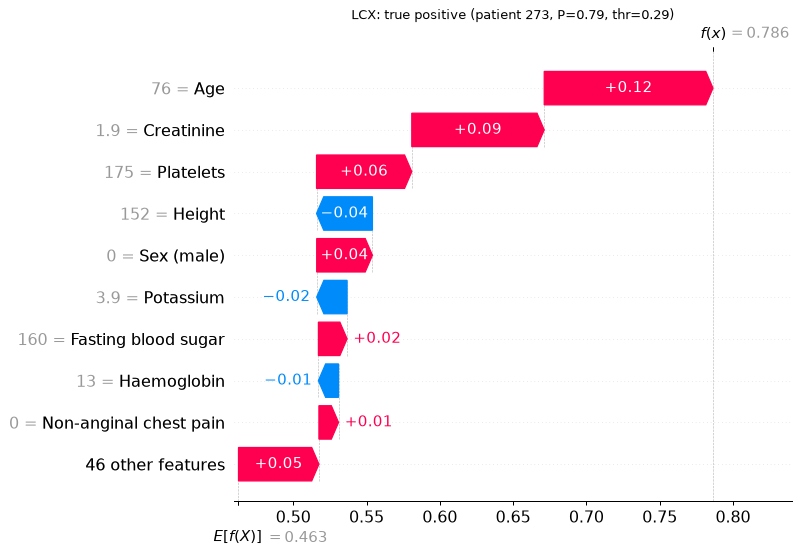

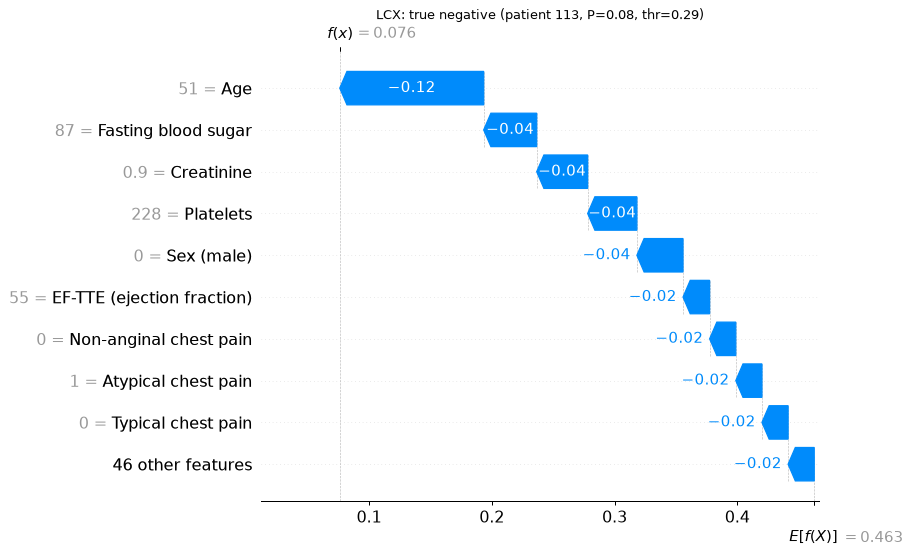

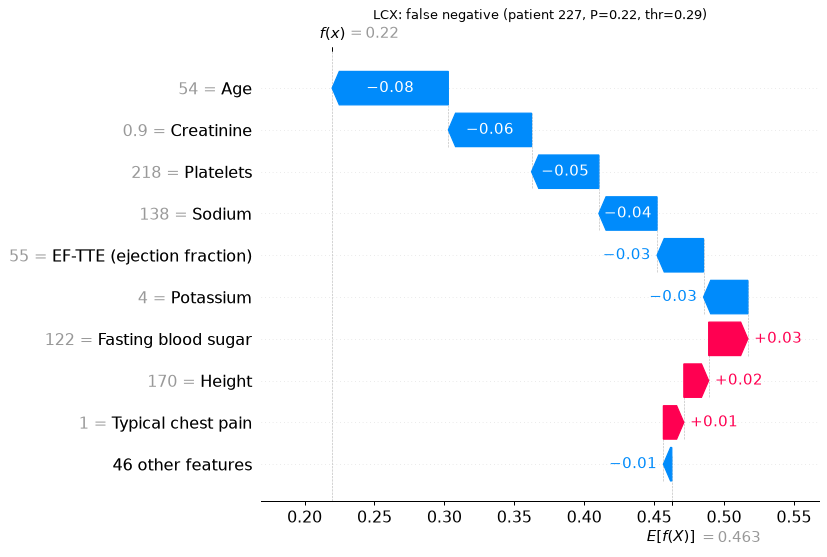

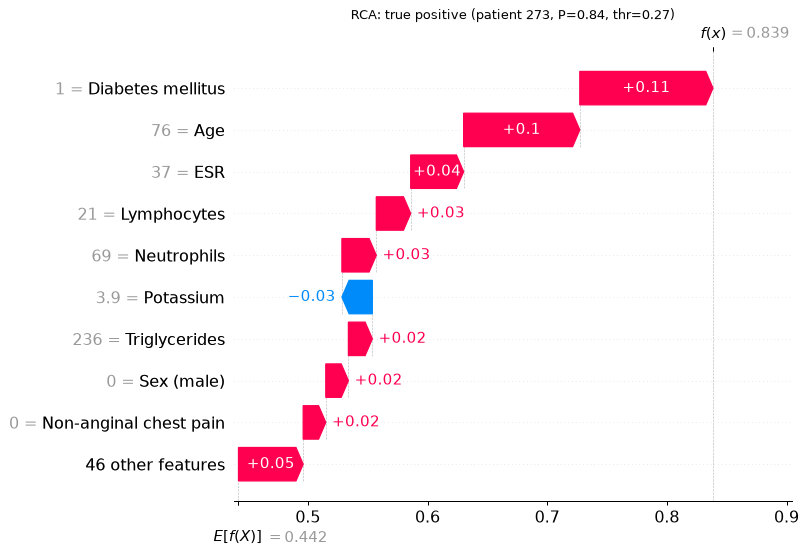

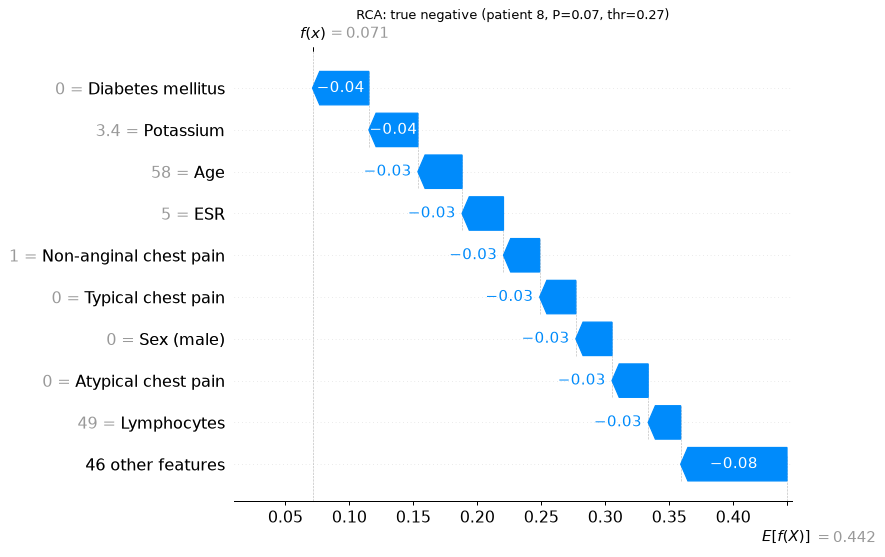

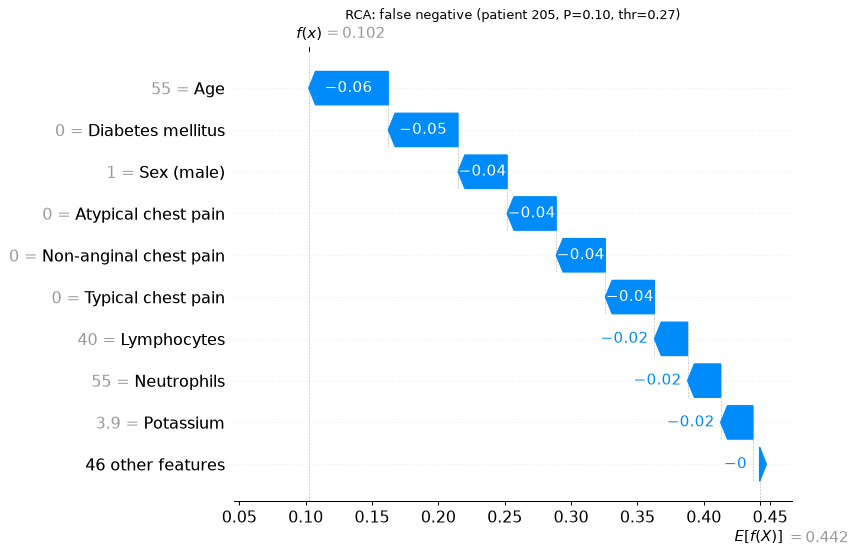

[lad] false negative -> patient 0: P=0.32 < 0.46; pulled down by Typical chest pain=0, Regional wall-motion abnormality=0, Age=53, EF-TTE (ejection fraction)=50
[lcx] false negative -> patient 227: P=0.22 < 0.29; pulled down by Age=54, Creatinine=0.9, Platelets=218, Sodium=138
[rca] false negative -> patient 205: P=0.10 < 0.27; pulled down by Age=55, Diabetes mellitus=0, Sex (male)=Male, Atypical chest pain=N


In [35]:
fn_notes = {}
for t in C.TARGETS:
    y, p, thr = Yte[t].to_numpy(), hold_probs[t], thresholds[t]["threshold"]
    contrib = hold_expl[t][1]
    expl = shap_explanation(contrib, Xte, explainers[t].p_ref)
    cases = {"true positive": np.where((y == 1) & (p >= thr))[0], "true negative": np.where((y == 0) & (p < thr))[0],
             "false negative": np.where((y == 1) & (p < thr))[0]}
    picks = {k: (v[np.argmax(p[v])] if k == "true positive" else v[np.argmin(p[v])] if k == "true negative"
                 else v[np.argmin(p[v])]) for k, v in cases.items() if len(v)}
    for k, i in picks.items():
        shap.plots.waterfall(expl[i], max_display=10, show=False)
        fig = plt.gcf()
        fig.axes[0].set_title(f"{C.TARGET_DISPLAY[t]}: {k} (patient {Xte.index[i]}, P={p[i]:.2f}, thr={thr:.2f})",
                              fontsize=10)
        show_fig(fig, f"shap_waterfall_{t}_{k.replace(' ', '_')}")
    if "false negative" in picks:
        i = picks["false negative"]
        row = contrib.iloc[i]
        down = row[row < 0].sort_values().index[:4]
        fn_notes[t] = (f"patient {Xte.index[i]}: P={p[i]:.2f} < {thr:.2f}; pulled down by "
                       + ", ".join(f"{C.FEATURES[f]['label']}={Xte.iloc[i][f]}" for f in down))
for t, s in fn_notes.items():
    print(f"[{t}] false negative -> {s}")

**Why were the false negatives missed?** The printed drivers show the usual pattern. A stenotic patient with
*no typical chest pain*, a normal ECG, preserved EF and no regional wall-motion abnormality "looks" like a
normal patient on non-invasive data. These are silent or atypical presentations of CAD, which clinical
pretest models also miss. That is why the CAD output has a **high-sensitivity threshold** (recall ≥ 0.90) as an
alternative operating point, and why a "Moderate" tier still prompts imaging.

### 4.5 Clinical sanity and stability
**Sanity:** the top features should make medical sense. **Stability:** we refit the final configuration on the
outer folds of the first two repeats, explain each fold's test patients, and report the mean ± std rank of the
top-10 features.

In [36]:
expected = {"typical_chest_pain", "age", "dm", "htn", "ef_tte", "region_rwma", "tinversion", "st_depression",
            "st_elevation", "q_wave", "atypical", "nonanginal", "sex", "fbs", "bp", "dlp"}
sanity = pd.DataFrame({C.TARGET_DISPLAY[t]: [f"{C.FEATURES[f]['label']}{' ✔' if f in expected else ''}"
                                             for f in glob_imp[t].index[:10]] for t in C.TARGETS},
                      index=range(1, 11))
sanity

,CAD (Cath),LAD,LCX,RCA
1,Typical chest pain ✔,Typical chest pain ✔,Age ✔,Diabetes mellitus ✔
2,EF-TTE (ejection fraction) ✔,Regional wall-motion abnormality ✔,Platelets,Age ✔
3,Age ✔,EF-TTE (ejection fraction) ✔,Fasting blood sugar ✔,ESR
4,Fasting blood sugar ✔,Atypical chest pain ✔,Creatinine,Neutrophils
5,ESR,Age ✔,Height,Lymphocytes
6,Hypertension ✔,Lymphocytes,Sodium,Potassium
7,Atypical chest pain ✔,T-wave inversion ✔,Sex (male) ✔,Haemoglobin
8,Non-anginal chest pain ✔,Non-anginal chest pain ✔,Typical chest pain ✔,Atypical chest pain ✔
9,Triglycerides,Neutrophils,Atypical chest pain ✔,Non-anginal chest pain ✔
10,Sex (male) ✔,Hypertension ✔,Non-anginal chest pain ✔,Typical chest pain ✔


In [37]:
def fold_importance(t, tr, te):
    Xf, Yf = Xtr.iloc[tr], Ytr.iloc[tr]
    cad_m = fit_final("cad", Xf, Yf)
    m = cad_m if t == "cad" else fit_final(t, Xf, Yf, cad_m)
    bg = Xf.iloc[:C.SHAP_BACKGROUND_SIZE]
    ce = PipelineExplainer(cad_m, bg, Xf)
    ex = ce if t == "cad" else (HierarchicalExplainer(m, ce, bg, Xf) if isinstance(m, HierarchicalVesselModel)
                                else PipelineExplainer(m, bg, Xf))
    return ex.explain_raw(Xtr.iloc[te])[1].abs().mean()

from joblib import Parallel, delayed
stab_splits = splits[: 2 * C.CV_SPLITS]
stability = {}
for t in C.TARGETS:
    imps = cached(f"stability_{t}_" + key_of(FINAL[t], FINAL["cad"], CAL, VESSEL_STRATEGY),
                  lambda: Parallel(n_jobs=C.N_JOBS)(delayed(fold_importance)(t, tr, te) for tr, te in stab_splits))
    ranks = pd.DataFrame(imps).rank(axis=1, ascending=False)
    top10 = ranks.mean().sort_values().index[:10]
    stability[t] = pd.DataFrame({"mean_rank": ranks[top10].mean().round(1), "std_rank": ranks[top10].std().round(1)})
    stability[t].index = [C.FEATURES[f]["label"] for f in top10]
pd.concat({C.TARGET_DISPLAY[t]: s for t, s in stability.items()}, axis=1)

CAD (Cath)                LAD                LCX                RCA         
                                  mean_rank std_rank mean_rank std_rank mean_rank std_rank mean_rank std_rank
Typical chest pain                      1.2      0.4       1.1      0.3       9.7      1.3       7.7      0.8
EF-TTE (ejection fraction)              3.4      2.9       2.9      1.1       NaN      NaN       NaN      NaN
Fasting blood sugar                     4.1      1.3       NaN      NaN       3.5      1.1       NaN      NaN
Age                                     4.3      1.6       5.1      0.3       1.0      0.0       2.6      0.7
Atypical chest pain                     5.0      1.4       3.4      0.8       9.7      1.3       7.7      0.8
Hypertension                            5.2      2.2       9.9      4.2       NaN      NaN       NaN      NaN
ESR                                     6.3      2.4       NaN      NaN       NaN      NaN       5.0      2.2
Non-anginal chest pain                  7.4      1.1       8.1      1.2       9.7      1.3       7.7      0.8
Sex (male)                              8.6      1.1       NaN      NaN       8.8      2.7       7.7      0.8
Triglycerides                          12.2      3.7       NaN      NaN       NaN      NaN      15.6     11.9
Regional wall-motion abnormality        NaN      NaN       2.6      0.5       NaN      NaN       NaN      NaN
T-wave inversion                        NaN      NaN       8.1      2.6       NaN      NaN       NaN      NaN
Neutrophils                             NaN      NaN       8.8      1.5       NaN      NaN       2.8      2.5
Lymphocytes                             NaN      NaN       9.4      3.2       NaN      NaN       NaN      NaN
Creatinine                              NaN      NaN       NaN      NaN       3.0      1.6       NaN      NaN
Platelets                               NaN      NaN       NaN      NaN       4.4      2.1       NaN      NaN
Height                                  NaN      NaN       NaN      NaN       6.5      2.9       NaN      NaN
HDL cholesterol                         NaN      NaN       NaN      NaN      10.5      4.2       NaN      NaN
Diabetes mellitus                       NaN      NaN       NaN      NaN       NaN      NaN       2.5      4.4
Dyslipidaemia                           NaN      NaN       NaN      NaN       NaN      NaN      16.6      6.3

### 4.6 Patient-level explanation: `explain_patient(patient_dict, k=8)`
For each target this returns the top-k raw features (`feature, label, group, value, unit, shap,
contribution_pct, direction`) plus the group totals. `shap` is in probability units (0.05 means
+5 percentage points of risk). `contribution_pct` is |shap| / Σ|shap| × 100.

In [38]:
import cardio_ml.predict as cp
cp._PREDICTOR = None                       # load the saved artifacts exactly like the dashboard will
patients = [{k: (v.item() if hasattr(v, "item") else v) for k, v in Xte.iloc[i].items()} for i in range(3)]
ep = cp.explain_patient(patients[0], k=8)
print(f"CAD prob {ep['cad']['prob']:.3f}; group totals {ep['cad']['group_totals']}")
pd.DataFrame(ep["cad"]["top_features"])

CAD prob 0.319; group totals {'demographic': 17.2, 'risk factor': 8.29, 'examination': 25.44, 'ECG': 9.57, 'lab': 27.75, 'echo': 11.74}


,feature,label,group,value,unit,shap,contribution_pct,direction
0,typical_chest_pain,Typical chest pain,examination,0,,-0.26991,16.19,lowers risk
1,age,Age,demographic,53.0,years,-0.20551,12.33,lowers risk
2,ef_tte,EF-TTE (ejection fraction),echo,50.0,%,0.17755,10.65,raises risk
3,fbs,Fasting blood sugar,lab,90.0,mg/dL,-0.15198,9.12,lowers risk
4,esr,ESR,lab,7.0,mm/h,-0.14933,8.96,lowers risk
5,htn,Hypertension,risk factor,1,,0.11884,7.13,raises risk
6,tg,Triglycerides,lab,250.0,mg/dL,0.09237,5.54,raises risk
7,nonanginal,Non-anginal chest pain,examination,N,,-0.07993,4.80,lowers risk


### 4.7 Speed (needed for real-time UI updates)
`predict_patient()` runs all 4 targets with explanations. In real-time mode SVM/TabPFN members are explained
by a LightGBM surrogate. Exact permutation SHAP takes several seconds per patient on CPU (measured in our
smoke test), so it is used only offline. The surrogate's fidelity R² is reported in 4.1. Tree and linear
members always use exact SHAP.

In [39]:
lat = cp.benchmark([{k: (v.item() if hasattr(v, "item") else v) for k, v in Xte.iloc[i].items()} for i in range(20)])
print(f"predict_patient() incl. explanations: mean {lat['mean_ms']:.1f} ms | p95 {lat['p95_ms']:.1f} ms | "
      f"max {lat['max_ms']:.1f} ms over {lat['n']} calls  (budget {C.LATENCY_BUDGET_MS} ms) -> "
      f"{'OK' if lat['p95_ms'] < C.LATENCY_BUDGET_MS else 'OVER BUDGET'}")

predict_patient() incl. explanations: mean 149.3 ms | p95 150.3 ms | max 246.3 ms over 60 calls  (budget 300 ms) -> OK


---
## Output contract
`predict_patient()` on 3 real hold-out rows, plus input-validation checks.

In [40]:
for i, pt in enumerate(patients):
    r = cp.predict_patient(pt)
    true = {t: int(Yte[t].iloc[i]) for t in C.TARGETS}
    print(f"\n--- hold-out patient {Xte.index[i]} | true labels {true}")
    print(json.dumps({k: v for k, v in r.items() if k not in ("explanations",)}, indent=1, ensure_ascii=False))
    print("CAD top-3:", [(e["label"], e["value"], e["direction"], e["contribution_pct"]) for e in r["explanations"]["cad"][:3]])

print("\nPartial input (missing fields -> schema defaults):",
      {t: cp.predict_patient({"Age": 67, "Sex": "Male", "Typical Chest Pain": 1})[t]["prob"] for t in C.TARGETS})
for bad in [{"age": "old"}, {"k": 9.5}, {"bbb": "XBBB"}, {"LAD": "Stenotic"}, {"cholesterol": 200}]:
    try:
        cp.predict_patient(bad)
    except ValueError as e:
        print("ValueError ✔", str(e)[:110])


--- hold-out patient 0 | true labels {'cad': 1, 'lad': 1, 'lcx': 0, 'rca': 1}
{
 "cad": {
  "prob": 0.3187,
  "threshold": 0.195,
  "label": "CAD",
  "risk_tier": "Moderate"
 },
 "lad": {
  "prob": 0.3247,
  "threshold": 0.4649999999999999,
  "label": "Normal"
 },
 "lcx": {
  "prob": 0.1765,
  "threshold": 0.29,
  "label": "Normal"
 },
 "rca": {
  "prob": 0.1785,
  "threshold": 0.27499999999999997,
  "label": "Normal"
 },
 "expected_stenotic_vessels": 0.68,
 "group_contributions": {
  "cad": {
   "demographic": 17.2,
   "risk factor": 8.29,
   "examination": 25.44,
   "ECG": 9.57,
   "lab": 27.75,
   "echo": 11.74
  },
  "lad": {
   "demographic": 11.16,
   "risk factor": 5.65,
   "examination": 30.93,
   "ECG": 16.96,
   "lab": 19.96,
   "echo": 15.33
  },
  "lcx": {
   "demographic": 31.99,
   "risk factor": 0.0,
   "examination": 17.6,
   "ECG": 0.0,
   "lab": 49.37,
   "echo": 1.04
  },
  "rca": {
   "demographic": 21.84,
   "risk factor": 18.88,
   "examination": 21.91,
   "ECG":


--- hold-out patient 4 | true labels {'cad': 0, 'lad': 0, 'lcx': 0, 'rca': 0}
{
 "cad": {
  "prob": 0.5771,
  "threshold": 0.195,
  "label": "CAD",
  "risk_tier": "Moderate"
 },
 "lad": {
  "prob": 0.0704,
  "threshold": 0.4649999999999999,
  "label": "Normal"
 },
 "lcx": {
  "prob": 0.1449,
  "threshold": 0.29,
  "label": "Normal"
 },
 "rca": {
  "prob": 0.0935,
  "threshold": 0.27499999999999997,
  "label": "Normal"
 },
 "expected_stenotic_vessels": 0.309,
 "group_contributions": {
  "cad": {
   "demographic": 17.2,
   "risk factor": 7.77,
   "examination": 25.37,
   "ECG": 8.38,
   "lab": 29.82,
   "echo": 11.46
  },
  "lad": {
   "demographic": 15.23,
   "risk factor": 5.4,
   "examination": 32.47,
   "ECG": 10.78,
   "lab": 21.05,
   "echo": 15.06
  },
  "lcx": {
   "demographic": 39.74,
   "risk factor": 0.0,
   "examination": 16.54,
   "ECG": 0.0,
   "lab": 42.56,
   "echo": 1.16
  },
  "rca": {
   "demographic": 27.49,
   "risk factor": 13.99,
   "examination": 26.24,
   "ECG"


--- hold-out patient 6 | true labels {'cad': 1, 'lad': 1, 'lcx': 0, 'rca': 0}
{
 "cad": {
  "prob": 0.9863,
  "threshold": 0.195,
  "label": "CAD",
  "risk_tier": "High"
 },
 "lad": {
  "prob": 0.984,
  "threshold": 0.4649999999999999,
  "label": "Stenotic"
 },
 "lcx": {
  "prob": 0.3563,
  "threshold": 0.29,
  "label": "Stenotic"
 },
 "rca": {
  "prob": 0.3564,
  "threshold": 0.27499999999999997,
  "label": "Stenotic"
 },
 "expected_stenotic_vessels": 1.697,
 "group_contributions": {
  "cad": {
   "demographic": 5.75,
   "risk factor": 7.18,
   "examination": 35.79,
   "ECG": 11.41,
   "lab": 25.61,
   "echo": 14.26
  },
  "lad": {
   "demographic": 1.75,
   "risk factor": 5.93,
   "examination": 18.83,
   "ECG": 28.09,
   "lab": 14.76,
   "echo": 30.64
  },
  "lcx": {
   "demographic": 17.95,
   "risk factor": 0.0,
   "examination": 13.26,
   "ECG": 0.0,
   "lab": 63.49,
   "echo": 5.3
  },
  "rca": {
   "demographic": 6.91,
   "risk factor": 18.29,
   "examination": 15.78,
   "ECG"


Partial input (missing fields -> schema defaults): {'cad': 0.9901, 'lad': 0.7167, 'lcx': 0.4371, 'rca': 0.4676}
ValueError ✔ 'age' must be numeric, got 'old'
ValueError ✔ 'k'=9.5 outside physiological limits [2, 7] mEq/L
ValueError ✔ Invalid value 'XBBB' for 'bbb'. Allowed: ['0', '1', '2', 'lbbb', 'n', 'rbbb']
ValueError ✔ 'LAD' is a diagnostic label (Cath/LAD/LCX/RCA) and can never be a model input
ValueError ✔ Unknown feature 'cholesterol'. Valid names: ['age', 'airway_disease', 'atypical', 'bbb', 'bmi', 'bp', 'bun', '


### Export metrics and the ML summary

In [41]:
def summ(res, y):
    s = res.summary(y)
    return {k: round(v, 4) for k, v in s.items()}

metrics = dict(
    dataset=C.DATASET_CITATION, fast_mode=C.FAST_MODE,
    validation=dict(holdout=C.TEST_SIZE, outer_cv=f"{C.CV_SPLITS}x{C.CV_REPEATS} repeated stratified",
                    inner_cv=f"{C.INNER_SPLITS}-fold Optuna ({C.N_TRIALS} trials)", bootstrap=C.N_BOOTSTRAP),
    tabpfn=dict(available=ok, reason=why),
    nested_cv={t: {m: summ(r, Ytr[t]) for m, r in zoo[t].items()} for t in C.TARGETS},
    selected={t: dict(model=FINAL[t].label, members=FINAL[t].members, selector=FINAL[t].selector,
                      smote=FINAL[t].smote, calibration=CAL[t],
                      vessel_strategy=VESSEL_STRATEGY if t in C.VESSELS else None,
                      nested_cv_of_selected=summ(zoo[t][best_model[t]], Ytr[t])) for t in C.TARGETS},
    vessel_strategies=strategy_table.astype(str).to_dict(orient="index"),
    calibration=cal_table.reset_index().astype({"method": str}).to_dict(orient="records"),
    final_oof={t: thresholds[t]["oof_metrics_at_threshold"] for t in C.TARGETS},
    holdout=holdout, latency_ms=lat,
    lime_shap_top5_overlap=lime_df.groupby("target").overlap_top5.mean().round(2).to_dict(),
)
(C.ARTIFACTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=1, default=str), encoding="utf-8")

def top5(t):
    return ", ".join(C.FEATURES[f]["label"] for f in glob_imp[t].index[:5])

res_rows = []
for t in C.TARGETS:
    nc = zoo[t][best_model[t]].summary(Ytr[t])
    h = holdout[t]
    res_rows.append({"Target": C.TARGET_DISPLAY[t],
                     "Model": FINAL[t].label + (f" · strategy {VESSEL_STRATEGY}" if t in C.VESSELS else ""),
                     "Nested-CV AUC": fmt(nc["auc_mean"], nc["auc_std"]),
                     "Hold-out AUC [95% CI]": f"{h['auc']['value']:.3f} [{h['auc']['ci_low']:.3f}, {h['auc']['ci_high']:.3f}]",
                     "Hold-out F1 [95% CI]": f"{h['f1']['value']:.3f} [{h['f1']['ci_low']:.3f}, {h['f1']['ci_high']:.3f}]",
                     "Hold-out Brier": f"{h['brier']['value']:.3f}",
                     "Hold-out Acc": f"{h['accuracy']['value']:.3f}",
                     "Top-5 drivers": top5(t)})
results_df = pd.DataFrame(res_rows).set_index("Target")

summary_md = f"""# Track A: ML summary (Steps 1–4)

**Data.** Extension of Z-Alizadeh Sani (UCI id 411): 303 patients, 55 features, 4 binary targets
(Cath/CAD 71%, LAD 58%, LCX 39%, RCA 38% positive). There are no missing values or duplicates, and nothing was
relabelled. `Exertional CP` is constant and was dropped. Every CAD patient has ≥ 1 stenotic vessel
({n_normal_but_vessel} "Normal" patient has a recorded stenotic vessel).

**Preprocessing.** Deterministic encoding (Y/N → 1/0, Sex, BBB one-hot, VHD / Function Class / Region RWMA ordinal),
plus engineered features: risk-factor count, ECG-abnormality count, ischaemic ECG, RWMA present, EF category,
chest-pain type, **Diamond–Forrester pretest probability**, TG/HDL, LDL/HDL, NLR, PLR, absolute lymphocytes and
**eGFR (CKD-EPI 2021)**. Linear and SVM models also get log1p, standardisation and drop weight/height/obesity
(collinear with BMI). Everything is a fitted-in-fold sklearn transformer inside `cardio_ml/`.

**Validation.** Stratified 20% hold-out (n={len(Xte)}, used once). On the 80% split: repeated stratified
{C.CV_SPLITS}×{C.CV_REPEATS} CV with **nested** Optuna tuning (inner {C.INNER_SPLITS}-fold), fold thresholds from
inner OOF, and all preprocessing inside the folds. Hold-out CIs use 1000 stratified bootstrap resamples. Labels are
never inputs (asserted before every fit).

**Models.** LR (ElasticNet), RBF-SVM, RF, ExtraTrees, LightGBM (in-fold early stopping), XGBoost, CatBoost,
soft-vote and stacking ensembles of the top 3 diverse families. TabPFN: {"used" if ok else "skipped (" + why[:90] + ")"}.
Vessel strategy: **{VESSEL_STRATEGY}** (A independent / B chain / C hierarchical P(CAD)·P(vessel|CAD)).
Calibration: {", ".join(f"{t}={CAL[t]}" for t in C.TARGETS)}.

**Results.**

{results_df.to_markdown()}

Risk tiers (calibrated CAD probability): Low < {tiers['low']:.2f} ≤ Moderate < {tiers['high']:.2f} ≤ High,
chosen so that ≤ 5% of CAD patients fall in Low and ≤ 10% of non-CAD patients fall in High (OOF).

**Explainability.** Exact TreeSHAP / LinearSHAP per member, propagated through ensembling, calibration and the
vessel hierarchy, expressed in probability points and mapped to raw clinical features and 6 physiological
groups. LIME agrees with SHAP on {lime_df.overlap_top5.mean():.1f} / 5 of the top-5 features on average.
`predict_patient()` with explanations takes **{lat['mean_ms']:.0f} ms** (p95 {lat['p95_ms']:.0f} ms) on CPU.

**Limitations.** Single-centre cohort (Tehran) of 303 patients with a high CAD prevalence (71%) from a
referral population, so the probabilities and tiers will not transfer to screening populations without
recalibration. There is no external validation. The hold-out has only 61 patients, so its CIs are wide.
Vessel labels are binary ≥ 50% stenosis with no lesion location, and Region RWMA is **not** an anatomical
map. The Diamond–Forrester table dates from 1979 and overestimates modern prevalence. Creatinine is assumed
to be in mg/dL. Height appears among LCX's top-5 drivers; with n = 303 this is most likely a spurious
correlation (e.g. confounded by sex), not a physiological effect. {C.DISCLAIMER}
"""
(C.ARTIFACTS_DIR / "ML_SUMMARY.md").write_text(summary_md, encoding="utf-8")
print("wrote metrics.json, ML_SUMMARY.md | total runtime %.1f min" % ((time.time() - T0) / 60))

wrote metrics.json, ML_SUMMARY.md | total runtime 15.4 min


---
## Results summary

In [42]:
print(f"FAST_MODE={C.FAST_MODE} | vessel strategy = {VESSEL_STRATEGY} | calibration = {CAL}")
print(f"Risk tiers: Low < {tiers['low']:.3f} <= Moderate < {tiers['high']:.3f} <= High")
print(f"Latency predict_patient() incl. SHAP: mean {lat['mean_ms']:.1f} ms, p95 {lat['p95_ms']:.1f} ms (CPU)")
print(f"TabPFN: {'used' if ok else 'skipped - ' + why}")
results_df

FAST_MODE=False | vessel strategy = A | calibration = {'cad': 'sigmoid', 'lad': 'sigmoid', 'lcx': 'sigmoid', 'rca': 'sigmoid'}
Risk tiers: Low < 0.077 <= Moderate < 0.820 <= High
Latency predict_patient() incl. SHAP: mean 149.3 ms, p95 150.3 ms (CPU)
TabPFN: skipped - tabpfn.errors.TabPFNLicenseError: TabPFN requires a one-time license acceptance to download


,Model,Nested-CV AUC,Hold-out AUC [95% CI],Hold-out F1 [95% CI],Hold-out Brier,Hold-out Acc,Top-5 drivers
Target,,,,,,,
CAD (Cath),stack(svm+lr+xgb),0.945 ± 0.036,"0.895 [0.806, 0.966]","0.905 [0.869, 0.945]",0.118,0.852,"Typical chest pain, EF-TTE (ejection fraction)..."
LAD,svm · strategy A,0.869 ± 0.053,"0.832 [0.725, 0.930]","0.805 [0.734, 0.877]",0.166,0.754,"Typical chest pain, Regional wall-motion abnor..."
LCX,rf · strategy A,0.740 ± 0.069,"0.768 [0.647, 0.878]","0.714 [0.641, 0.788]",0.193,0.672,"Age, Platelets, Fasting blood sugar, Creatinin..."
RCA,vote(lr+svm+et) · strategy A,0.737 ± 0.054,"0.741 [0.598, 0.868]","0.596 [0.491, 0.702]",0.191,0.623,"Diabetes mellitus, Age, ESR, Neutrophils, Lymp..."


---
## Step 5: Prediction → anatomy mapping layer
`cardio_ml/anatomy.py` turns `predict_patient()` output into a deterministic, render-ready **scene state** for the
3D heart and torso. All mesh names, texts and visual constants come from `artifacts/anatomy_map.json`, the single
source of truth. Nothing is retrained and no model, threshold or metric changes. This section is
self-contained: it loads only the saved artifacts, exactly as the dashboard will.

**Rules, enforced in code and tests:**
* Only the LAD, LCX and RCA are risk-coloured, each uniformly along its whole length (the data has no lesion location).
* The left main and other branches are neutral.
* No feature (in particular Region RWMA) ever selects a vessel or a location.
* Colour shows calibrated risk on one shared scale. A separate non-colour flag (badge, outline, pulse) marks prob ≥ the vessel's threshold.

In [1]:
import json, time, subprocess, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cardio_ml import config as C, anatomy as A, plots as P
from cardio_ml.data import load_raw, get_features
from cardio_ml.predict import predict_patient

amap = A.load_map()
print("schema  ->", A.write_schema())
print("spec    ->", A.write_asset_spec())
df5, _ = load_raw()
X5 = get_features(df5)
te5 = json.loads((C.ARTIFACTS_DIR / "split.json").read_text())["test_idx"]
hold = {i: {k: (v.item() if hasattr(v, "item") else v) for k, v in X5.iloc[i].items()} for i in te5}
preds = {i: predict_patient(p, k=A.N_FEATURES) for i, p in hold.items()}
tiers = pd.Series({i: p["cad"]["risk_tier"] for i, p in preds.items()})
print("hold-out risk tiers:", tiers.value_counts().to_dict())
pd.DataFrame([dict(vessel=v["key"], mesh=", ".join(v["mesh_names"]), anchor=v["camera_anchor"],
                   reliability=A.reliability_badge(amap["_holdout_auc"][v["key"]], amap),
                   holdout_auc=round(amap["_holdout_auc"][v["key"]], 3), description=v["short_description"])
              for v in amap["vessels"]]).set_index("vessel")

schema  -> C:\Users\shrim\OneDrive\Desktop\IIT_MANDI\artifacts\scene_state.schema.json
spec    -> C:\Users\shrim\OneDrive\Desktop\IIT_MANDI\artifacts\ASSET_SPEC.md


hold-out risk tiers: {'High': 42, 'Moderate': 15, 'Low': 4}


,mesh,anchor,reliability,holdout_auc,description
vessel,,,,,
lad,Coronary_LAD,Anchor_LAD,Moderate,0.832,Supplies blood to the front of the heart.
lcx,Coronary_LCX,Anchor_LCX,Moderate,0.768,Supplies blood to the side and back of the heart.
rca,Coronary_RCA,Anchor_RCA,Limited,0.741,Supplies blood to the right side and bottom of...


### 5.1–5.2 Colour scale, flags and reliability
The colour is interpolated in CIELAB, so lightness falls strictly as probability rises. It therefore reads
correctly in greyscale and with colour-vision deficiency. Each vessel's threshold appears as a marker on the
same scale.

L* by probability: [90.1, 85.8, 81.6, 77.4, 70.2, 62.9, 55.6, 49.4, 43.3, 37.2, 30.9]


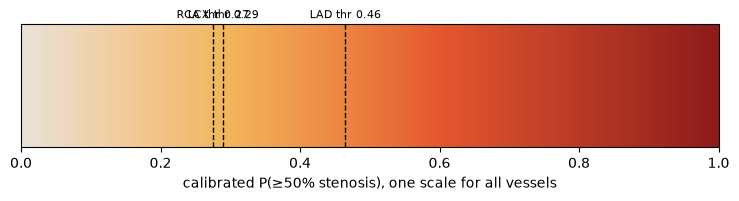

In [2]:
ps = np.linspace(0, 1, 11)
print("L* by probability:", [round(A.lightness(A.color_for(p)), 1) for p in ps])
fig, ax = plt.subplots(figsize=(9, 1.6))
grid = np.linspace(0, 1, 200)
ax.imshow([[tuple(int(A.color_for(g)[i:i + 2], 16) / 255 for i in (1, 3, 5)) for g in grid]],
          aspect="auto", extent=(0, 1, 0, 1))
any_pred = next(iter(preds.values()))
for v in C.VESSELS:
    thr = any_pred[v]["threshold"]
    ax.axvline(thr, color="k", ls="--", lw=1)
    ax.text(thr, 1.05, f"{v.upper()} thr {thr:.2f}", ha="center", fontsize=8, transform=ax.get_xaxis_transform())
ax.set_yticks([])
ax.set_xlabel("calibrated P(≥50% stenosis), one scale for all vessels")
P.save(fig, "step5_color_scale")
plt.show()

### 5.3 Scene state for three hold-out patients (the median patient of the Low, Moderate and High CAD tiers) + schematic previews
The 2D schematic is a sanity preview and documentation figure, not the final UI. Vessels are coloured exactly as
the scene state specifies. Flagged vessels get a dashed halo and a ⚠ badge, a cue that does not depend on colour.

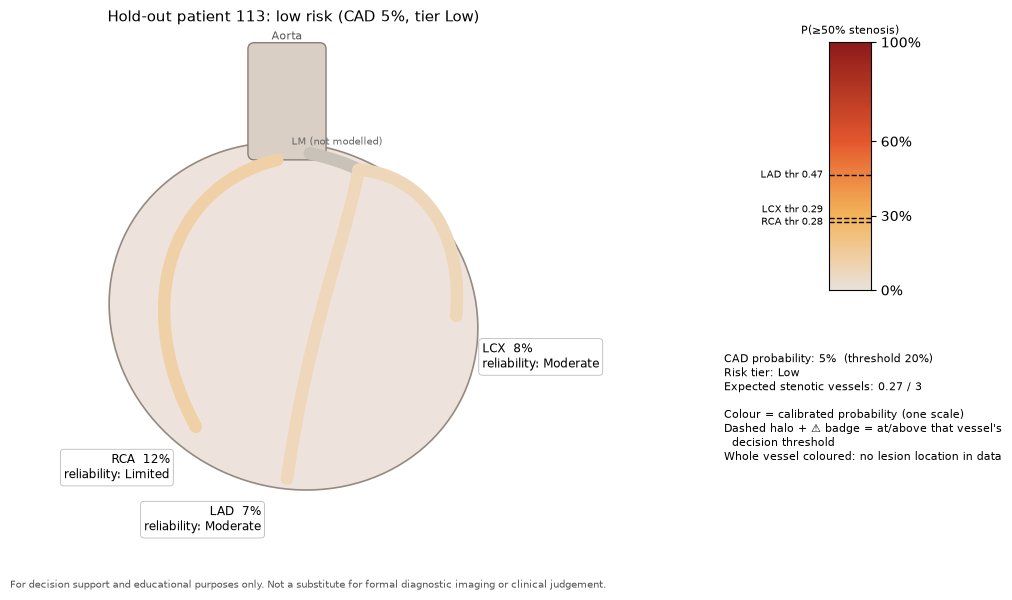

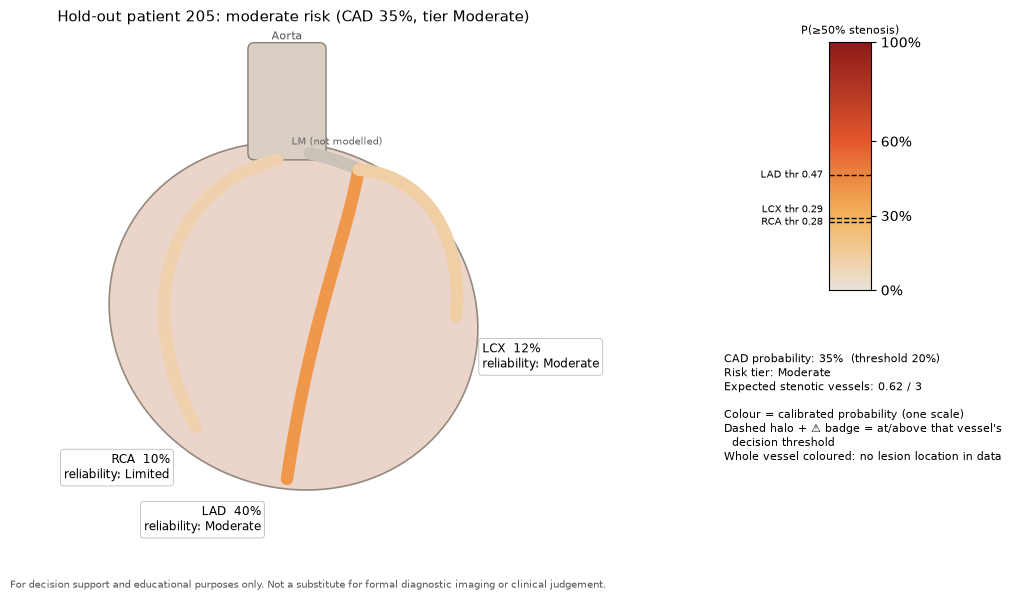

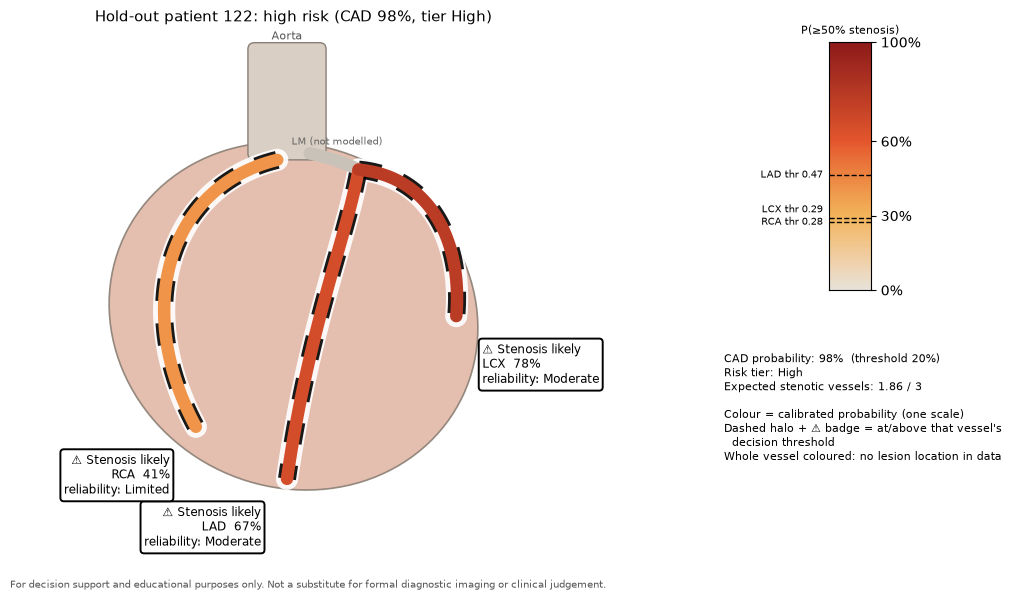

patient    prob  threshold  flagged    color reliability  \
case     vessel                                                             
low      LAD         113  0.0726      0.465    False  #EED7BA    Moderate   
         LCX         113  0.0761      0.290    False  #EED6B8    Moderate   
         RCA         113  0.1170      0.275    False  #F0D0A7     Limited   
moderate LAD         205  0.3983      0.465    False  #EF974B    Moderate   
         LCX         205  0.1238      0.290    False  #F0CFA4    Moderate   
         RCA         205  0.1023      0.275    False  #EFD2AD     Limited   
high     LAD         122  0.6707      0.465     True  #D44D2B    Moderate   
         LCX         122  0.7849      0.290     True  #BB3C25    Moderate   
         RCA         122  0.4097      0.275     True  #EF9449     Limited   

                                       top_driver  scene_ms  
case     vessel                                              
low      LAD                  Atypical chest pain      0.42  
         LCX                                  Age      0.42  
         RCA                                  Age      0.42  
moderate LAD                   Typical chest pain      0.47  
         LCX                                  Age      0.47  
         RCA                                  Age      0.47  
high     LAD     Regional wall-motion abnormality      0.72  
         LCX                                  Age      0.72  
         RCA                    Diabetes mellitus      0.72

In [3]:
cases = {}
for tier in ["Low", "Moderate", "High"]:
    cand = tiers[tiers == tier].index
    ranked = sorted(cand, key=lambda i: preds[i]["cad"]["prob"])
    cases[tier.lower()] = int(ranked[len(ranked) // 2])          # median patient of the tier
rows = []
for case, i in cases.items():
    t0 = time.perf_counter()
    sc = A.scene_state(preds[i], "cad")
    ms = (time.perf_counter() - t0) * 1000
    fig = P.coronary_schematic(sc, f"Hold-out patient {i}: {case} risk (CAD {sc['heart']['cad_prob']:.0%}, tier {sc['heart']['risk_tier']})")
    P.save(fig, f"coronary_schematic_{case}")
    plt.show()
    for v in C.VESSELS:
        vv = sc["vessels"][v]
        rows.append(dict(case=case, patient=i, vessel=v.upper(), prob=vv["prob"], threshold=vv["threshold"],
                         flagged=vv["flagged"], color=vv["color"], reliability=vv["reliability"],
                         top_driver=vv["top_drivers"][0]["label"], scene_ms=round(ms, 2)))
pd.DataFrame(rows).set_index(["case", "vessel"])

In [4]:
sc = A.scene_state(preds[cases["high"]], "lad", show_territories=True)
print(json.dumps({"vessels.lad": {k: sc["vessels"]["lad"][k] for k in ("prob", "threshold", "flagged", "reliability", "top_drivers")},
                  "meshes.Coronary_LAD": {k: v for k, v in sc["meshes"]["Coronary_LAD"].items() if k != "tooltip"},
                  "meshes.Territory_LAD": {k: v for k, v in sc["meshes"]["Territory_LAD"].items() if k != "tooltip"},
                  "meshes.Coronary_LM": sc["meshes"]["Coronary_LM"],
                  "heart": sc["heart"], "regions(focus=LAD)": sc["regions"], "disclaimer": sc["disclaimer"]},
                 indent=1, ensure_ascii=False))

{
 "vessels.lad": {
  "prob": 0.6707,
  "threshold": 0.465,
  "flagged": true,
  "reliability": "Moderate",
  "top_drivers": [
   {
    "label": "Regional wall-motion abnormality",
    "value": 2,
    "unit": "regions",
    "contribution_pct": 17.25,
    "direction": "raises risk"
   },
   {
    "label": "Atypical chest pain",
    "value": "Y",
    "unit": "",
    "contribution_pct": 10.53,
    "direction": "lowers risk"
   },
   {
    "label": "Typical chest pain",
    "value": 0,
    "unit": "",
    "contribution_pct": 9.07,
    "direction": "lowers risk"
   }
  ]
 },
 "meshes.Coronary_LAD": {
  "color": "#D44D2B",
  "opacity": 1.0,
  "flagged": true,
  "emissive": 0.45,
  "pulse_hz": 0.984,
  "outline_color": "#FFFFFF",
  "badge": "Stenosis likely",
  "target": "lad",
  "visible": true
 },
 "meshes.Territory_LAD": {
  "color": "#D44D2B",
  "emissive": 0.0,
  "pulse_hz": 0.0,
  "flagged": false,
  "target": "lad",
  "outline_color": null,
  "badge": null,
  "visible": true,
  "opacit

### 5.4 What-if engine (for the dashboard sliders)
Only modifiable factors can change. Weight and BMI stay consistent through height, Obesity is re-derived, and
quitting smoking sets ex-smoker. Results are **model-estimated changes, not treatment effects**: the models are
correlational.

applied: {'ldl': 90, 'bp': 120, 'current_smoker': 0, 'fbs': 95} | derived: {} | tier: ('High', 'High')
note: Model-estimated change only. The models are correlational, not causal: this is NOT a treatment effect and must not be read as the benefit of an intervention.


,before,after,delta
cad,0.9835,0.9677,-0.0158
lad,0.6707,0.6135,-0.0572
lcx,0.7849,0.7387,-0.0462
rca,0.4097,0.4097,0.0000


rejected ✔ 'age' is not modifiable in what-if analysis (only ['bmi', 'bp', 'current_smoker', 'dlp', 'dm', 'fbs', 'hdl', 'htn', 'ldl', 'tg', 'weight']). Age, sex, ECG and echo findings cannot be changed.


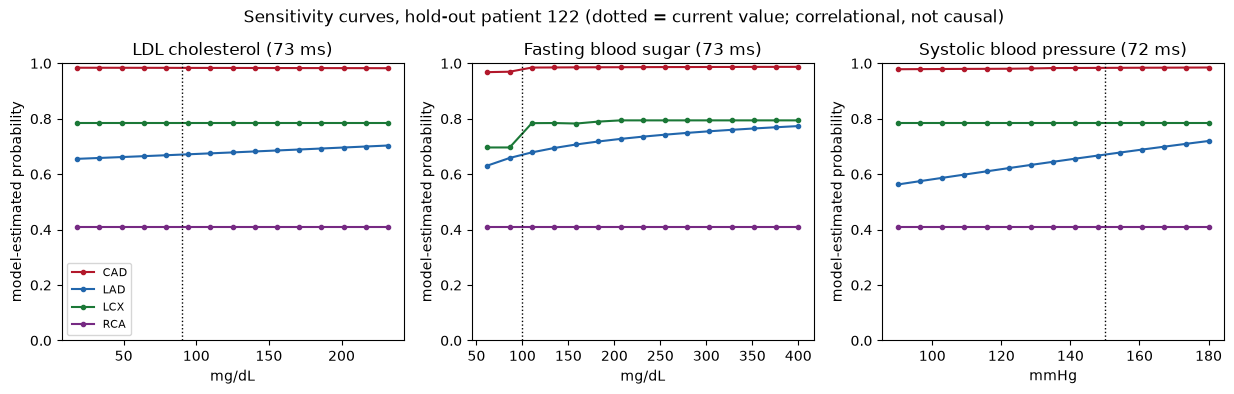

In [5]:
i = cases["high"]
wi = A.what_if(hold[i], {"ldl": 90, "bp": 120, "current_smoker": 0, "fbs": 95})
print("applied:", wi["applied_changes"], "| derived:", wi["derived_updates"], "| tier:", wi["tier_change"])
print("note:", wi["note"])
display(pd.DataFrame({t: dict(before=wi["before"][t]["prob"], after=wi["after"][t]["prob"],
                              delta=wi["delta_per_target"][t]) for t in C.TARGETS}).T)
try:
    A.what_if(hold[i], {"age": 45})
except ValueError as e:
    print("rejected ✔", e)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, feat in zip(axes, ["ldl", "fbs", "bp"]):
    t0 = time.perf_counter()
    curve = pd.DataFrame(A.sensitivity_curve(hold[i], feat)).set_index("value")
    dt = time.perf_counter() - t0
    for t in C.TARGETS:
        ax.plot(curve.index, curve[t], marker="o", ms=3, label=t.upper(), color=P.PALETTE[t])
    ax.axvline(hold[i][feat], color="k", ls=":", lw=1)
    ax.set(title=f"{C.FEATURES[feat]['label']} ({dt * 1000:.0f} ms)", xlabel=C.FEATURES[feat]["unit"],
           ylabel="model-estimated probability", ylim=(0, 1))
axes[0].legend(fontsize=8)
fig.suptitle(f"Sensitivity curves, hold-out patient {i} (dotted = current value; correlational, not causal)", y=1.03)
P.save(fig, "step5_sensitivity_curves")
plt.show()

Some curves are flat by design. A vessel model that never received a feature (RCA uses 10 selected features) cannot
respond to it. This is shown honestly, not smoothed over.

### 5.5–5.6 Contracts and tests
`ASSET_SPEC.md` is generated from the map. `validate_glb_names()` checks the Step 6 `.glb` for required meshes and
anchors, the triangle and size budget, Draco compression and one material per mesh. The pytest suite covers the 10
required checks plus purity, the validator and a "no hard-coded mesh names" check.

In [6]:
req = A.required_names(amap)
print(f"{len(req['meshes'])} required meshes, {len(req['anchors'])} anchors, optional: {req['optional_meshes']}")
t0 = time.perf_counter()
for _ in range(500):
    A.scene_state(preds[cases["moderate"]])
print(f"scene_state latency: {(time.perf_counter() - t0) / 500 * 1000:.3f} ms (budget {amap['style']['latency_budget_ms']['scene_state']} ms)")
res = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "-p", "no:cacheprovider", "-W", "ignore", "--color=no"],
                     capture_output=True, text=True, cwd=str(C.ROOT))
print(res.stdout.strip().splitlines()[-1])

16 required meshes, 13 anchors, optional: ['Coronary_Branches']
scene_state latency: 0.227 ms (budget 5 ms)


15 passed in 5.05s
